# Thực nghiệm bổ sung: thêm ràng buộc thứ tự bên trong nhóm biến nền $\mathbf{Z}$

**Notebook gốc:** `notebook/00_MASTER_Causal_PGM_Educational_Intervention.ipynb` (mục 8, Tables A–C).
Notebook này chạy lại **đúng** pipeline B0 / H1 / H2 với **một** thay đổi duy nhất: bộ cạnh cấm.

**Vì sao cần.** Ở bản gốc, ràng buộc chỉ cấm cạnh đi ngược *giữa các tầng* ($Y \to \{T, Z\}$, $T \to Z$). Bên trong
tầng $\mathbf{Z}$ thuật toán được tự do chọn chiều, nên B0 học ra các cạnh vô lý về nhân quả như
`Học phí → Tuổi` hay `Tuổi → Học vấn mẹ` (Hình 8.1 bản gốc). Dữ liệu quan sát không xác định được chiều giữa các biến
cùng tầng; chiều đó phải đến từ tri thức miền.

**Ràng buộc thêm (chia tầng $\mathbf{Z}$ theo thời điểm hình thành):**

| Tầng con | Biến | Lý do |
| :--- | :--- | :--- |
| Z-a (gia đình, có trước nhất) | $Z_4$ Học vấn mẹ | Hình thành trước khi sinh viên ra đời; **không** biến nào gây ra nó |
| Z-b (nhân khẩu) | $Z_5$ Tuổi > 20 | Chỉ có thể chịu ảnh hưởng của hoàn cảnh gia đình ($Z_4$) |
| Z-c (trước nhập học) | $Z_1$ Điểm vào | Hình thành trước khi có tình trạng tài chính lúc nhập học |
| Z-d (lúc nhập học) | $Z_2$ Debtor, $Z_3$ Học phí đúng hạn | Cùng thời điểm; cho phép cả hai chiều giữa chúng |

Cạnh từ tầng con sau về tầng con trước bị cấm, tức thêm 9 cạnh cấm:
$\{Z_1, Z_2, Z_3, Z_5\} \to Z_4$, $\{Z_1, Z_2, Z_3\} \to Z_5$, $\{Z_2, Z_3\} \to Z_1$.
Ràng buộc này áp **chung** cho B0 (ExpertKnowledge) và H2 (mặt nạ $M$), giống bản gốc.

**Điều cần kiểm chứng:** vì mọi $Z$ đều có trước $T$, đổi chiều cạnh $Z \to Z$ **không** được làm đổi tính hợp lệ của
tập điều chỉnh. Kỳ vọng: ATE gần như không đổi, đồ thị dễ đọc hơn. Bảng so sánh với bản gốc nằm ở cuối notebook.

**Cách chạy:** *Runtime ▸ Run all* trên Colab (≈ 5 phút CPU, không cần GPU), hoặc *Restart & Run All* cục bộ.
Kết quả ghi vào `artifacts_rang_buoc_z/`; dùng lại split gốc `artifacts/splits/split_seed_<seed>.json` để so sánh ghép cặp.


In [2]:
# ==============================================================================
# 0. Cài đặt: tự nhận biết Colab, tải repo và thư viện; cục bộ thì chuyển về thư mục gốc repo
# ==============================================================================
import os
import sys
import subprocess
from pathlib import Path

REPO_URL = 'https://github.com/HoangVuSnape/04_Probabilistic_GrModel.git'
REPO_DIR = Path('/content/04_Probabilistic_GrModel')
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    if not REPO_DIR.exists():
        ket_qua = subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, str(REPO_DIR)], capture_output=True, text=True)
        if ket_qua.returncode != 0:
            raise RuntimeError('Không clone được repo (repo private?). Cách khác: nén thư mục dự án thành zip, tải lên '
                               'Colab, giải nén vào /content/04_Probabilistic_GrModel rồi chạy lại cell này.\n'
                               + ket_qua.stderr)
    os.chdir(REPO_DIR)
    # Chỉ ghim hai thư viện mà kết quả phụ thuộc; các gói còn lại dùng bản có sẵn của Colab.
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pgmpy==1.1.2', 'dowhy==0.14'], check=True)
else:
    if Path.cwd().name == 'notebook':
        os.chdir('..')

for can_co in ['data/uci_697.csv'] + [f'artifacts/splits/split_seed_{s}.json' for s in (42, 43, 44, 45, 46)]:
    assert Path(can_co).exists(), f'Thiếu {can_co} — cần chạy notebook ở thư mục gốc của repo.'
print('Thư mục làm việc:', Path.cwd(), '| Colab:', IN_COLAB)


Thư mục làm việc: /content/04_Probabilistic_GrModel | Colab: True


In [3]:
# ==============================================================================
# Mục 8: Thư viện cho pipeline B0 / H1 / H2
# ==============================================================================
import sys
import os
import subprocess
from pathlib import Path


import time
import json
import math
import random
import itertools
import warnings
from dataclasses import dataclass, field, asdict
from typing import Dict, List, Tuple, Any, Optional

import numpy as np
import pandas as pd
import scipy.stats as stats
import networkx as nx
import matplotlib.pyplot as plt

import sklearn.metrics as metrics
from sklearn.model_selection import StratifiedKFold, train_test_split

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

import pgmpy
try:
    from pgmpy.models import DiscreteBayesianNetwork
except ImportError:
    from pgmpy.models import BayesianNetwork as DiscreteBayesianNetwork

from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

if hasattr(sys.stdout, 'reconfigure'):
    sys.stdout.reconfigure(encoding='utf-8')

import dowhy
from dowhy import CausalModel

warnings.filterwarnings('ignore')
print(f'PyTorch Version: {torch.__version__} | CUDA Available: {torch.cuda.is_available()}')
print(f'pgmpy Version: {pgmpy.__version__} | DoWhy Version: {dowhy.__version__}')
print('Thư viện cho pipeline B0/H1/H2 đã sẵn sàng.')

import seaborn as sns
from typing import Set
from IPython.display import display
plt.rcParams['font.family'] = 'DejaVu Sans'


/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


PyTorch Version: 2.14.1+cpu | CUDA Available: False
pgmpy Version: 1.1.2 | DoWhy Version: 0.14
Thư viện cho pipeline B0/H1/H2 đã sẵn sàng.


<a id='s8-a'></a>
### 8.A. Cấu hình chung, dữ liệu 7 biến và 5 split (Slide 54, 56)
#### 8.A.1. Đặc tả hợp đồng dữ liệu và thiết lập đối tượng Config duy nhất
Theo quy định tại **Slide 54 & 56**, mọi phép thử nghiệm phải chia sẻ chung một đối tượng `Config` duy nhất và tuân thủ chặt chẽ trật tự thời gian đo lường biến số:
* **Outcome ($Y$):** `Target` (`Graduate = 1`, `Dropout = 0`). Nhóm `Enrolled` đã được loại bỏ hoàn toàn để bảo đảm biến đầu ra nhị phân rõ ràng.
* **Treatment ($T$):** `Scholarship holder` ($0/1$).
* **Confounders ($Z$ - Biến nền đo lường tại thời điểm nhập học):**
  * $Z_1$: `Admission grade` (Rời rạc hóa thành 3 nhóm: $[0, 120) \to 0$, $[120, 140) \to 1$, $[\ge 140) \to 2$).
  * $Z_2$: `Debtor` ($0/1$ - Nợ tiền học phí hoặc các khoản nợ của trường).
  * $Z_3$: `Tuition fees up to date` ($0/1$ - Tình trạng đóng học phí đúng hạn).
  * $Z_4$: `Mother's qualification` ($0/1$ - Trình độ học vấn của mẹ: $\ge 13$ là Đại học/Sau đại học $\to 1$, ngược lại $\to 0$).
  * $Z_5$: `Age at enrollment` ($0/1$ - Độ tuổi khi nhập học: $> 20 \to 1$, $\le 20 \to 0$).
* **Phân chia dữ liệu (70% Train / 15% Val / 15% Test):** Phân chia stratified theo $Y$ và $T$ qua 5 mầm ngẫu nhiên (`seeds = [42, 43, 44, 45, 46]`). Tiền xử lý chỉ `fit` trên tập Train của từng seed.


In [4]:
# ==============================================================================
# Mục 8.A: Cấu hình chung & thư mục artifacts
# ==============================================================================
@dataclass(frozen=True)
class Config:
    # Hạt giống ngẫu nhiên cho 5 paired runs
    seeds: Tuple[int, ...] = (42, 43, 44, 45, 46)
    
    # Tỷ lệ phân chia tập dữ liệu
    train_ratio: float = 0.70
    val_ratio: float = 0.15
    test_ratio: float = 0.15
    
    # Nguồn dữ liệu UCI 697
    data_url: str = 'https://archive.ics.uci.edu/static/public/697/data.csv'
    data_local_path: str = 'data/uci_697.csv'
    
    # Danh mục biến số trong Primary DAG (7 nút)
    confounders: Tuple[str, ...] = ('Z1', 'Z2', 'Z3', 'Z4', 'Z5')
    treatment: str = 'T'
    outcome: str = 'Y'
    all_nodes: Tuple[str, ...] = ('Z1', 'Z2', 'Z3', 'Z4', 'Z5', 'T', 'Y')
    
    # Thư mục lưu trữ artifacts
    artifacts_dir: str = 'artifacts_rang_buoc_z'
    splits_dir: str = 'artifacts/splits'  # dùng lại ĐÚNG 5 split gốc để so sánh ghép cặp
    tables_dir: str = 'artifacts_rang_buoc_z/tables'
    checkpoints_dir: str = 'artifacts_rang_buoc_z/checkpoints'
    graphs_dir: str = 'artifacts_rang_buoc_z/graphs'
    
    # Siêu tham số Mô hình B0 (học DAG truyền thống + CPD BDeu)
    b0_ess: int = 5  # Equivalent Sample Size cho BDeu prior (dùng chung cho B0 và H2)
    b0_score_grid: Tuple[str, ...] = ('BIC', 'BDeu', 'K2')  # chọn trên VALIDATION
    required_edges: Tuple[Tuple[str, str], ...] = (('T', 'Y'),)  # giả thuyết cần ước lượng, áp cho cả B0 và H2

    # Siêu tham số Mô hình H1 (Neural CPD)
    h1_hidden_dim: int = 32
    h1_dropout: float = 0.2
    h1_lr: float = 0.005
    h1_weight_decay: float = 1e-4
    h1_batch_size: int = 64
    h1_epochs: int = 150
    h1_patience: int = 15
    h1_refute_sims: int = 3

    # Siêu tham số Mô hình H2 (NOTEARS-MLP phi tuyến)
    h2_hidden: int = 10
    h2_lambda_grid: Tuple[float, ...] = (1e-3, 1e-4)  # chọn trên VALIDATION của seed 42, rồi đóng băng
    h2_threshold_grid: Tuple[float, ...] = (0.1, 0.2, 0.3, 0.5, 0.8)  # chọn trên VALIDATION từng seed
    h2_lr: float = 0.01
    h2_inner_iters: int = 300
    h2_max_outer: int = 12
    h2_h_tol: float = 1e-6
    h2_rho_max: float = 1e+16

    # Tham số đánh giá & kiểm định
    n_bootstrap: int = 1000
    placebo_simulations: int = 30
    subset_fraction: float = 0.80

def init_directories(cfg: Config):
    for p in [cfg.artifacts_dir, cfg.splits_dir, cfg.tables_dir, cfg.checkpoints_dir, cfg.graphs_dir, 'data', 'splits']:
        Path(p).mkdir(parents=True, exist_ok=True)

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

GLOBAL_CONFIG = Config()
init_directories(GLOBAL_CONFIG)
print('Khởi tạo thành công cấu hình toàn cục ExperimentConfig.')


Khởi tạo thành công cấu hình toàn cục ExperimentConfig.


In [5]:
# ==============================================================================
# Mục 8.A: Nạp dữ liệu & mã hóa 7 biến
# ==============================================================================
def load_and_preprocess_uci697(cfg: Config) -> pd.DataFrame:
    """
    Nạp dữ liệu từ UCI hoặc cache nội bộ, lọc cohort Dropout/Graduate,
    binarize Outcome và tạo 7 biến số theo đúng hợp đồng nhân quả.
    """
    local_p = Path(cfg.data_local_path)
    if local_p.exists():
        print(f'Nạp dữ liệu từ cache cục bộ: {local_p}')
        df_raw = pd.read_csv(local_p, sep=None, engine='python')
    else:
        print(f'Tải dữ liệu từ UCI Repository: {cfg.data_url}')
        try:
            df_raw = pd.read_csv(cfg.data_url, sep=None, engine='python')
        except Exception:
            df_raw = pd.read_csv(cfg.data_url, sep=';')
        # Lưu cache
        local_p.parent.mkdir(parents=True, exist_ok=True)
        df_raw.to_csv(local_p, index=False, sep=';')
    
    # Chuẩn hóa tên cột để xử lý BOM và ký tự đặc biệt
    aliases = {
        'admissiongrade': 'Admission grade',
        'ageatenrollment': 'Age at enrollment',
        'scholarshipholder': 'Scholarship holder',
        'target': 'Target',
        'debtor': 'Debtor',
        'tuitionfeesuptodate': 'Tuition fees up to date',
        'mothersqualification': "Mother's qualification",
    }
    renamed = {}
    for c in df_raw.columns:
        k = ''.join(ch for ch in str(c).lower() if ch.isalnum())
        renamed[c] = aliases.get(k, str(c).strip())
    df_raw = df_raw.rename(columns=renamed)
    
    # 1. Lọc bỏ nhóm 'Enrolled' (loại bỏ trạng thái trung gian chưa rõ kết quả)
    initial_count = len(df_raw)
    df_clean = df_raw[df_raw['Target'].isin(['Dropout', 'Graduate'])].copy()
    filtered_count = len(df_clean)
    print(f'[Eligibility Audit] Ban đầu: {initial_count} dòng -> Sau khi loại Enrolled: {filtered_count} dòng (Loại bỏ {initial_count - filtered_count} dòng).')
    
    # 2. Xây dựng 7 biến số Primary DAG
    df_model = pd.DataFrame(index=df_clean.index)
    
    # Z1: Admission grade (3 nhóm: < 120 -> 0; 120-140 -> 1; >= 140 -> 2)
    adm = pd.to_numeric(df_clean['Admission grade'], errors='coerce')
    df_model['Z1'] = pd.cut(adm, bins=[-np.inf, 120.0, 140.0, np.inf], labels=[0, 1, 2]).astype(int)
    
    # Z2: Debtor (0/1)
    df_model['Z2'] = df_clean['Debtor'].astype(int)
    
    # Z3: Tuition fees up to date (0/1)
    df_model['Z3'] = df_clean['Tuition fees up to date'].astype(int)
    
    # Z4: Mother's qualification (>= 13 là Đại học/Sau đại học -> 1, còn lại -> 0)
    mq = pd.to_numeric(df_clean["Mother's qualification"], errors='coerce')
    df_model['Z4'] = (mq >= 13).astype(int)
    
    # Z5: Age at enrollment (> 20 -> 1, <= 20 -> 0)
    age = pd.to_numeric(df_clean['Age at enrollment'], errors='coerce')
    df_model['Z5'] = (age > 20).astype(int)
    
    # T: Treatment - Scholarship holder (0/1)
    df_model['T'] = df_clean['Scholarship holder'].astype(int)
    
    # Y: Outcome - Target (Graduate = 1, Dropout = 0)
    df_model['Y'] = df_clean['Target'].map({'Graduate': 1, 'Dropout': 0}).astype(int)
    
    # Sắp xếp lại thứ tự cột chuẩn xác
    cols = list(cfg.all_nodes)
    df_model = df_model[cols].reset_index(drop=True)
    
    # Kiểm tra missing values
    assert df_model.isnull().sum().sum() == 0, 'Lỗi: Tồn tại giá trị NaN sau tiền xử lý!'
    print(f'[Sanity Check] Kích thước tập dữ liệu hoàn chỉnh: {df_model.shape}')
    print('[Class Balance] Phân bố nhãn Outcome Y:', df_model['Y'].value_counts().to_dict())
    print('[Treatment Balance] Phân bố can thiệp T:', df_model['T'].value_counts().to_dict())
    return df_model

PRIMARY_DF = load_and_preprocess_uci697(GLOBAL_CONFIG)
PRIMARY_DF.head()


Nạp dữ liệu từ cache cục bộ: data/uci_697.csv
[Eligibility Audit] Ban đầu: 4424 dòng -> Sau khi loại Enrolled: 3630 dòng (Loại bỏ 794 dòng).
[Sanity Check] Kích thước tập dữ liệu hoàn chỉnh: (3630, 7)
[Class Balance] Phân bố nhãn Outcome Y: {1: 2209, 0: 1421}
[Treatment Balance] Phân bố can thiệp T: {0: 2661, 1: 969}


,Z1,Z2,Z3,Z4,Z5,T,Y
0,1,0,1,1,0,0,0
1,2,0,0,0,0,0,1
2,1,0,0,1,0,0,0
3,0,0,1,1,0,0,1
4,2,0,1,1,1,0,1


In [6]:
# ==============================================================================
# Mục 8.A: 5 split phân tầng 70/15/15
# ==============================================================================
def get_or_create_splits(df: pd.DataFrame, cfg: Config) -> Dict[int, Dict[str, List[int]]]:
    """
    Tạo hoặc nạp lại phân chia dữ liệu 70/15/15 cho 5 seeds.
    Phân tầng (Stratified) dựa trên tổ hợp của Y và T để đảm bảo cân bằng can thiệp.
    """
    splits_dict = {}
    n_samples = len(df)
    strata = df['Y'].astype(str) + '_' + df['T'].astype(str)
    
    for seed in cfg.seeds:
        split_file = Path(cfg.splits_dir) / f'split_seed_{seed}.json'
        alt_split_file = Path('splits') / f'split_seed_{seed}.json'
        
        if split_file.exists():
            with open(split_file, 'r', encoding='utf-8') as f:
                split_data = json.load(f)
        elif alt_split_file.exists():
            with open(alt_split_file, 'r', encoding='utf-8') as f:
                split_data = json.load(f)
        else:
            set_seed(seed)
            indices = np.arange(n_samples)
            
            # Bước 1: Tách 70% Train và 30% Temp (Val + Test)
            train_idx, temp_idx = train_test_split(
                indices, test_size=(cfg.val_ratio + cfg.test_ratio),
                random_state=seed, stratify=strata
            )
            
            # Bước 2: Tách 30% Temp thành 15% Val và 15% Test
            temp_strata = strata.iloc[temp_idx]
            val_idx, test_idx = train_test_split(
                temp_idx, test_size=0.5,
                random_state=seed, stratify=temp_strata
            )
            
            split_data = {
                'seed': seed,
                'train_indices': train_idx.tolist(),
                'val_indices': val_idx.tolist(),
                'test_indices': test_idx.tolist()
            }
            
            # Lưu file json
            for target_path in [split_file, alt_split_file]:
                target_path.parent.mkdir(parents=True, exist_ok=True)
                with open(target_path, 'w', encoding='utf-8') as f:
                    json.dump(split_data, f, indent=2)
        
        # Kiểm tra tính toàn vẹn (Sanity checks)
        tr_set = set(split_data['train_indices'])
        va_set = set(split_data['val_indices'])
        te_set = set(split_data['test_indices'])
        assert len(tr_set.intersection(va_set)) == 0, f'Seed {seed}: Train và Val bị giao nhau!'
        assert len(tr_set.intersection(te_set)) == 0, f'Seed {seed}: Train và Test bị giao nhau!'
        assert len(va_set.intersection(te_set)) == 0, f'Seed {seed}: Val và Test bị giao nhau!'
        assert len(tr_set) + len(va_set) + len(te_set) == n_samples, f'Seed {seed}: Không phủ hết tập mẫu!'
        
        splits_dict[seed] = split_data
        print(f'Seed {seed}: Train = {len(tr_set)} | Val = {len(va_set)} | Test = {len(te_set)}')
    
    return splits_dict

CACHED_SPLITS = get_or_create_splits(PRIMARY_DF, GLOBAL_CONFIG)
print('Toàn bộ 5 phân chia Train/Val/Test đã được xác nhận và đóng băng.')


Seed 42: Train = 2541 | Val = 544 | Test = 545
Seed 43: Train = 2541 | Val = 544 | Test = 545
Seed 44: Train = 2541 | Val = 544 | Test = 545
Seed 45: Train = 2541 | Val = 544 | Test = 545
Seed 46: Train = 2541 | Val = 544 | Test = 545
Toàn bộ 5 phân chia Train/Val/Test đã được xác nhận và đóng băng.


<a id='s8-b'></a>
### 8.B. Mô hình B0 — học DAG truyền thống + CPD BDeu (Slide 57, 59)
#### 8.B.1. Học cấu trúc trên TRAIN, chọn thiết lập trên VALIDATION (Slide 57, 59)
1. **Ràng buộc miền khai báo TRƯỚC khi học** (dùng chung cho B0 và H2):
   * Cạnh cấm theo thời gian: $Y \to \{T, Z_k\}$ (kết cục không gây ra quá khứ) và $T \to Z_k$ (học bổng không thay đổi đặc điểm lúc nhập học).
   * **Mới — thứ tự bên trong $\mathbf{Z}$:** cấm $\{Z_1, Z_2, Z_3, Z_5\} \to Z_4$, $\{Z_1, Z_2, Z_3\} \to Z_5$, $\{Z_2, Z_3\} \to Z_1$ (xem bảng tầng con ở đầu notebook).
   * Cạnh bắt buộc: $T \to Y$ — đây là giả thuyết nhân quả cần ước lượng; nếu không ép, ATE của mô hình sẽ bằng 0 theo định nghĩa.
2. **Thuật toán:** `pgmpy.HillClimbSearch` với `ExpertKnowledge(forbidden_edges, required_edges)`; lưới hàm điểm {BIC, BDeu($ESS=5$), K2}.
3. **Chọn trên VALIDATION:** với mỗi hàm điểm, khớp CPD BDeu trên TRAIN và tính log-likelihood toàn mạng trên VALIDATION; chọn hàm điểm tốt nhất rồi **đóng băng** DAG trước khi chạm TEST.
4. **Domain DAG 11 cạnh** ($Z_k \to T$, $Z_k \to Y$, $T \to Y$) chỉ còn là **tham chiếu** để so sánh với DAG học được.
5. **CPD:** BDeu với $ESS = 5$ (Slide 67), `check_model()` cho mọi mô hình.
6. **Can thiệp chuẩn hóa trên $C_{\text{test}}$ (Slide 61):** vì mặt nạ cấm $T \to Z$, mọi biến trong $\text{Pa}(Y) \setminus \{T\}$ là tiền can thiệp nên là tập điều chỉnh cửa sau hợp lệ trên DAG đã học:
   $$q_m(t, C_i) = P_m(Y=1 \mid T=t, \text{Pa}(Y)\setminus T = C_i), \quad \text{risk}_m(t) = \tfrac{1}{n_{\text{test}}}\sum_i q_m(t, C_i), \quad \text{ATE}_m = \text{risk}_m(1) - \text{risk}_m(0)$$
   DoWhy `identify_effect` được chạy trên **chính DAG đã học** của từng run để xác nhận định danh (mục 8.E).
7. **Giả định:** không có nhiễu ẩn ngoài các biến trong đồ thị; tính nhất quán (consistency); overlap (được kiểm tra theo từng hồ sơ test ở Table B).


In [7]:
# ==============================================================================
# Mục 8.B: B0 — HillClimb + CPD BDeu + truy vấn vector hóa
# ==============================================================================
from pgmpy.estimators import HillClimbSearch, BIC, BDeu, K2
from pgmpy.causal_discovery import ExpertKnowledge


def build_b0_dag(cfg: Config) -> nx.DiGraph:
    """Domain DAG tham chiếu 7 nút (11 cạnh) — chỉ dùng để đối chiếu với DAG B0 học được, KHÔNG dùng để fit B0."""
    # Đại ý: sơ đồ vẽ tay 11 cạnh (5 Z -> T, 5 Z -> Y, T -> Y); chỉ để so với B0, không dùng để fit.
    dag = nx.DiGraph()
    dag.add_nodes_from(cfg.all_nodes)
    for z in cfg.confounders:
        dag.add_edge(z, cfg.treatment)
        dag.add_edge(z, cfg.outcome)
    dag.add_edge(cfg.treatment, cfg.outcome)
    assert nx.is_directed_acyclic_graph(dag), 'Lỗi nghiêm trọng: Đồ thị B0 bị chu trình!'
    assert len(dag.edges()) == 11, f'Lỗi: Số cạnh Domain DAG phải là 11, thực tế có {len(dag.edges())}'
    return dag


def temporal_forbidden_edges(cfg: Config) -> List[Tuple[str, str]]:
    """
    Danh sách cạnh cấm theo trật tự thời gian Z (nhập học) -> T (học bổng) -> Y (kết cục), dùng CHUNG cho B0 và H2:
    cấm Y -> (T, Z), T -> Z, và (MỚI) các cạnh Z -> Z đi ngược thứ tự Z4 -> Z5 -> Z1 -> {Z2, Z3}.
    """
    # Đại ý: cạnh cấm theo thời gian. Y không gây ra gì; T không gây ra Z.
    cam = [(cfg.outcome, v) for v in cfg.all_nodes if v != cfg.outcome]
    cam += [(cfg.treatment, z) for z in cfg.confounders]
    # MỚI: thứ tự bên trong nhóm Z theo thời điểm hình thành (Z4 -> Z5 -> Z1 -> {Z2, Z3}).
    # Học vấn mẹ (Z4) có trước nhất; Tuổi (Z5) chỉ có thể chịu ảnh hưởng từ Z4; Điểm vào (Z1) có trước
    # tình trạng tài chính lúc nhập học (Z2 Debtor, Z3 Học phí); Z2 và Z3 cùng thời điểm nên không cấm.
    cam += [(z, 'Z4') for z in ('Z1', 'Z2', 'Z3', 'Z5')]
    cam += [(z, 'Z5') for z in ('Z1', 'Z2', 'Z3')]
    cam += [(z, 'Z1') for z in ('Z2', 'Z3')]
    return cam


def fit_discrete_bayesian_model(model: DiscreteBayesianNetwork, train_df: pd.DataFrame, ess: float = 5.0) -> DiscreteBayesianNetwork:
    """Khớp tham số mạng Bayes rời rạc với BDeu smoothing tương thích đa phiên bản pgmpy."""
    try:
        from pgmpy.parameter_estimator import DiscreteBayesianEstimator
        estimator = DiscreteBayesianEstimator(prior_type='BDeu', equivalent_sample_size=ess)
        model.fit(train_df, estimator=estimator)
    except Exception:
        from pgmpy.estimators import BayesianEstimator
        model.fit(train_df, estimator=BayesianEstimator, prior_type='BDeu', equivalent_sample_size=ess)
    assert model.check_model(), 'Lỗi: check_model() thất bại!'
    return model


def fit_bn_on_dag(train_df: pd.DataFrame, dag: nx.DiGraph, cfg: Config) -> DiscreteBayesianNetwork:
    """Khớp CPD BDeu (cùng họ ước lượng và cùng ESS cho B0 và H2) trên một DAG cho trước."""
    # Đại ý: điền bảng CPD cho mọi nút bằng BDeu (ESS = cfg.b0_ess = 5) trên TRAIN.
    model = DiscreteBayesianNetwork(list(dag.edges()))
    model.add_nodes_from(cfg.all_nodes)
    return fit_discrete_bayesian_model(model, train_df[list(cfg.all_nodes)], ess=cfg.b0_ess)


def validation_log_likelihood(model: DiscreteBayesianNetwork, df: pd.DataFrame) -> float:
    """Log-likelihood của toàn mạng trên một tập dữ liệu: sum_i sum_v log P(x_v | pa(x_v))."""
    # Đại ý: cộng log P(giá trị | cha) của mọi nút, mọi SV. Càng lớn (ít âm) thì mạng khớp dữ liệu càng tốt.
    tong = 0.0
    for nut in model.nodes():
        cpd = model.get_cpds(nut)
        chi_so = tuple(np.searchsorted(np.array(cpd.state_names[v]), df[v].values) for v in cpd.variables)
        tong += float(np.log(cpd.values[chi_so]).sum())
    return tong


def learn_b0_dag(train_df: pd.DataFrame, val_df: pd.DataFrame, cfg: Config) -> Tuple[nx.DiGraph, str, List[Dict[str, Any]]]:
    """
    Học DAG B0 trên TRAIN bằng pgmpy HillClimbSearch (Slide 57, 59):
      - ràng buộc: cạnh cấm theo thời gian + cạnh bắt buộc T -> Y (giả thuyết cần ước lượng);
      - lưới hàm điểm cfg.b0_score_grid; chọn hàm điểm có log-likelihood VALIDATION cao nhất, rồi đóng băng.
    Trả ra: DAG được chọn, tên hàm điểm, bảng các ứng viên.
    """
    # Đại ý: thử 3 hàm điểm (BIC, BDeu, K2), mỗi hàm cho một sơ đồ; giữ sơ đồ có log-likelihood VAL cao nhất.
    # Biến chính: tri_thuc = cạnh cấm + cạnh bắt buộc T -> Y; ung_vien = bảng 3 ứng viên; tot_nhat = (điểm VAL, tên, DAG).
    tri_thuc = ExpertKnowledge(forbidden_edges=temporal_forbidden_edges(cfg), required_edges=list(cfg.required_edges))
    du_lieu = train_df[list(cfg.all_nodes)]
    ham_diem = {'BIC': BIC(du_lieu), 'BDeu': BDeu(du_lieu, equivalent_sample_size=cfg.b0_ess), 'K2': K2(du_lieu)}
    ung_vien: List[Dict[str, Any]] = []
    tot_nhat: Optional[Tuple[float, str, nx.DiGraph]] = None
    for ten in cfg.b0_score_grid:
        uoc_luong = HillClimbSearch(du_lieu).estimate(scoring_method=ham_diem[ten], expert_knowledge=tri_thuc, show_progress=False)
        dag = nx.DiGraph(list(uoc_luong.edges()))
        dag.add_nodes_from(cfg.all_nodes)
        ll_val = validation_log_likelihood(fit_bn_on_dag(train_df, dag, cfg), val_df)
        ung_vien.append({'Score': ten, 'Edges': len(dag.edges()), 'Val_LogLik': ll_val,
                         'Pa(Y)': sorted(dag.predecessors(cfg.outcome))})
        if tot_nhat is None or ll_val > tot_nhat[0]:
            tot_nhat = (ll_val, ten, dag)
    assert tot_nhat is not None and nx.is_directed_acyclic_graph(tot_nhat[2])
    for (u, v) in temporal_forbidden_edges(cfg):
        assert not tot_nhat[2].has_edge(u, v), f'Vi phạm ràng buộc thời gian: {u}->{v}'
    return tot_nhat[2], tot_nhat[1], ung_vien


def save_graph_artifacts(dag: nx.DiGraph, name: str, cfg: Config, extra: Optional[Dict[str, Any]] = None) -> None:
    """Lưu danh sách cạnh (và thông tin phụ) của một DAG ra artifacts/graphs/<name>.json (Slide 44, 76)."""
    # Đại ý: lưu danh sách cạnh ra JSON để nạp lại và kiểm tra sau.
    noi_dung = {'nodes': list(cfg.all_nodes), 'edges': [list(e) for e in dag.edges()]}
    if extra:
        noi_dung.update(extra)
    with open(Path(cfg.graphs_dir) / f'{name}.json', 'w', encoding='utf-8') as tep:
        json.dump(noi_dung, tep, indent=2, ensure_ascii=False, default=str)


def query_model_effects(model: DiscreteBayesianNetwork, df: pd.DataFrame, cfg: Config) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Truy vấn vector hóa từ CPD của Y:
    - q0, q1: q_m(t, C_i) = P_m(Y=1 | T=t, Pa(Y)\\{T} = C_i) — bằng P(Y=1 | do(T=t), C_i) vì trong DAG đã học
      Pa(Y)\\{T} gồm các biến tiền can thiệp (mặt nạ cấm T->Z) nên là một tập điều chỉnh cửa sau hợp lệ;
    - pred: P(Y=1 | T_obs, Pa(Y)) cho dự báo ngoài mẫu.
    """
    # Đại ý: tra bảng CPD của Y cho từng SV, với T ép = 0 và ép = 1.
    # Biến chính: q0, q1 = P(Y=1 | do(T=0/1), hồ sơ SV); pred_probs = dùng T thật, để chấm AUROC.
    cpd_y = model.get_cpds(cfg.outcome)
    parents = cpd_y.variables[1:]
    n_rows = len(df)
    if not parents:
        p = float(cpd_y.values[1])
        return np.full(n_rows, p), np.full(n_rows, p), np.full(n_rows, p)
    # Chỉ số đầu = 1 là cột "Y = 1"; các chỉ số sau là trạng thái của từng nút cha.
    idx_0, idx_1, idx_pred = [1], [1], [1]
    for p in parents:
        if p == cfg.treatment:
            idx_0.append(np.zeros(n_rows, dtype=int))
            idx_1.append(np.ones(n_rows, dtype=int))
            idx_pred.append(df[cfg.treatment].values.astype(int))
        else:
            vals = df[p].values.astype(int)
            idx_0.append(vals)
            idx_1.append(vals)
            idx_pred.append(vals)
    q0 = cpd_y.values[tuple(idx_0)].astype(np.float64)
    q1 = cpd_y.values[tuple(idx_1)].astype(np.float64)
    pred_probs = cpd_y.values[tuple(idx_pred)].astype(np.float64)
    return q0, q1, pred_probs


# Kiểm thử nhanh trên Seed 42
# Chạy thử B0 trên seed 42: học sơ đồ, điền CPD, tính ATE trên TEST.
sample_split = CACHED_SPLITS[42]
sample_train = PRIMARY_DF.iloc[sample_split['train_indices']].reset_index(drop=True)
sample_val = PRIMARY_DF.iloc[sample_split['val_indices']].reset_index(drop=True)
sample_test = PRIMARY_DF.iloc[sample_split['test_indices']].reset_index(drop=True)
sample_b0_dag, sample_score, sample_candidates = learn_b0_dag(sample_train, sample_val, GLOBAL_CONFIG)
print('[B0 Seed 42] Ứng viên HillClimb (chọn theo log-likelihood VALIDATION):')
print(pd.DataFrame(sample_candidates).to_string(index=False))
print(f'[B0 Seed 42] Chọn hàm điểm = {sample_score} | Cạnh học được: {sorted(sample_b0_dag.edges())}')
sample_b0 = fit_bn_on_dag(sample_train, sample_b0_dag, GLOBAL_CONFIG)
q0, q1, sample_pred = query_model_effects(sample_b0, sample_test, GLOBAL_CONFIG)
print(f'[B0 Seed 42 Test] Risk(do(T=0)): {np.mean(q0):.4f} | Risk(do(T=1)): {np.mean(q1):.4f} | ATE: {np.mean(q1) - np.mean(q0):+.4f}')


[B0 Seed 42] Ứng viên HillClimb (chọn theo log-likelihood VALIDATION):
Score  Edges   Val_LogLik           Pa(Y)
  BIC      9 -2211.107526     [T, Z3, Z5]
 BDeu      9 -2211.107526     [T, Z3, Z5]
   K2     11 -2208.371996 [T, Z2, Z3, Z5]
[B0 Seed 42] Chọn hàm điểm = K2 | Cạnh học được: [('T', 'Y'), ('Z2', 'Y'), ('Z3', 'T'), ('Z3', 'Y'), ('Z3', 'Z2'), ('Z4', 'Z1'), ('Z4', 'Z5'), ('Z5', 'T'), ('Z5', 'Y'), ('Z5', 'Z1'), ('Z5', 'Z3')]
[B0 Seed 42 Test] Risk(do(T=0)): 0.5397 | Risk(do(T=1)): 0.7863 | ATE: +0.2467


<a id='s8-c'></a>
### 8.C. Mô hình H1 — CPD nơ-ron trên DAG B0 (Slide 60)
* Với mỗi run, **sao chép DAG B0 của chính run đó** và chỉ thay CPD của $Y$; mọi CPD khác, trạng thái và split giữ nguyên.
* **Đầu vào MLP = đúng $\text{Pa}(Y)$** của DAG B0 (biến 3 trạng thái mã hóa one-hot) — số chiều đầu vào vì thế thay đổi theo DAG học được.
* **Kiến trúc:** Linear → BatchNorm → ReLU → Dropout(0.2) → Linear → ReLU → Linear; **loss** `BCEWithLogitsLoss`; **Adam** (lr 0.005, weight decay 1e-4), batch 64, tối đa 150 epoch.
* **Dừng sớm trên VALIDATION** (patience 15); số tham số, epoch tốt nhất và đường loss train/val được lưu trong checkpoint `artifacts/checkpoints/h1_seed<seed>.pt`.
* Liệt kê mọi cấu hình cha để tạo `TabularCPD` chuẩn hóa, gắn vào bản sao B0 và `check_model()`; xác suất được chặn trong $[10^{-4}, 1-10^{-4}]$ (chặn số học, tách biệt với làm mịn CPD — Slide 79).


In [8]:
# ==============================================================================
# Mục 8.C: H1 — CPD nơ-ron cho Y trên DAG B0
# ==============================================================================
class NeuralCPDModule(nn.Module):
    """MLP ước lượng P(Y=1 | Pa(Y)); số chiều đầu vào phụ thuộc tập cha Pa(Y) của DAG B0 trong từng run."""
    def __init__(self, in_features: int, hidden_dim: int = 32, dropout: float = 0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Linear(hidden_dim // 2, 1)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x).squeeze(-1)


# Số trạng thái của mỗi biến: Z1 có 3 mức, còn lại nhị phân.
STATE_CARD: Dict[str, int] = {'Z1': 3, 'Z2': 2, 'Z3': 2, 'Z4': 2, 'Z5': 2, 'T': 2, 'Y': 2}


def encode_h1_features(df: pd.DataFrame, parents: List[str]) -> torch.Tensor:
    """Mã hóa DUY NHẤT các nút cha của Y (Slide 60): biến 3 trạng thái -> one-hot, biến nhị phân giữ nguyên."""
    # Đại ý: Z1 (3 mức) -> one-hot 3 cột; biến nhị phân giữ 1 cột. Với Pa(Y) = {T, Z1, Z2, Z3} ra 6 cột.
    khoi: List[np.ndarray] = []
    for p in parents:
        if STATE_CARD[p] > 2:
            khoi.append(np.eye(STATE_CARD[p])[df[p].values.astype(int)])
        else:
            khoi.append(df[[p]].values.astype(np.float32))
    return torch.tensor(np.hstack(khoi).astype(np.float32), dtype=torch.float32)


def h1_input_dim(parents: List[str]) -> int:
    """Số chiều đầu vào của MLP ứng với tập cha."""
    return int(sum(STATE_CARD[p] if STATE_CARD[p] > 2 else 1 for p in parents))


def train_h1_mlp(train_df: pd.DataFrame, val_df: pd.DataFrame, parents: List[str], cfg: Config,
                 seed: int, dung_som: bool = True) -> Tuple[NeuralCPDModule, Dict[str, Any]]:
    """Huấn luyện MLP trên TRAIN (BCE), theo dõi loss VALIDATION sau mỗi epoch; trả về mô hình và nhật ký.
    dung_som=True (mặc định, dùng cho Tables A–C): dừng khi VAL không cải thiện cfg.h1_patience epoch và khôi phục
    trọng số tốt nhất. dung_som=False: chạy đủ cfg.h1_epochs và giữ trọng số của epoch cuối (để so sánh, mục 8.E2)."""
    # Đại ý: huấn luyện MLP dự đoán P(Y=1 | cha của Y). Sau mỗi epoch tính loss trên VAL;
    # nếu VAL không giảm suốt cfg.h1_patience = 15 epoch thì dừng sớm và lấy lại trọng số tốt nhất.
    # Biến chính: best_val, best_epoch, best_w = loss VAL nhỏ nhất, epoch đó, trọng số đó; train_hist, val_hist = đường loss.
    set_seed(seed)
    X_train = encode_h1_features(train_df, parents)
    y_train = torch.tensor(train_df['Y'].values, dtype=torch.float32)
    X_val = encode_h1_features(val_df, parents)
    y_val = torch.tensor(val_df['Y'].values, dtype=torch.float32)
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=cfg.h1_batch_size, shuffle=True)
    model = NeuralCPDModule(h1_input_dim(parents), cfg.h1_hidden_dim, cfg.h1_dropout)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=cfg.h1_lr, weight_decay=cfg.h1_weight_decay)
    best_val, patience, best_w, best_epoch = float('inf'), 0, None, 0
    train_hist: List[float] = []
    val_hist: List[float] = []
    for epoch in range(cfg.h1_epochs):
        model.train()
        tong, dem = 0.0, 0
        for bx, by in loader:
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            optimizer.step()
            tong += loss.item() * len(by)
            dem += len(by)
        model.eval()
        with torch.no_grad():
            v_loss = criterion(model(X_val), y_val).item()
        train_hist.append(tong / dem)
        val_hist.append(v_loss)
        if v_loss < best_val:
            best_val, best_epoch, patience = v_loss, epoch, 0
            best_w = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            patience += 1
            if dung_som and patience >= cfg.h1_patience:
                break
    if dung_som:
        model.load_state_dict(best_w)
    model.eval()
    nhat_ky = {'parents': parents, 'in_features': h1_input_dim(parents), 'early_stopping': dung_som, 'best_epoch': best_epoch,
               'best_val_bce': best_val, 'epochs_run': len(val_hist), 'train_loss': train_hist, 'val_loss': val_hist,
               'n_params': int(sum(p.numel() for p in model.parameters())),
               'architecture': f'Linear({h1_input_dim(parents)},{cfg.h1_hidden_dim})-BN-ReLU-Dropout({cfg.h1_dropout})-'
                               f'Linear({cfg.h1_hidden_dim},{cfg.h1_hidden_dim // 2})-ReLU-Linear(.,1)',
               'optimizer': f'Adam(lr={cfg.h1_lr}, weight_decay={cfg.h1_weight_decay}), batch={cfg.h1_batch_size}'}
    return model, nhat_ky


def save_h1_checkpoint(model: NeuralCPDModule, nhat_ky: Dict[str, Any], seed: int, cfg: Config,
                       hau_to: str = '') -> Path:
    """Lưu trọng số + cấu hình H1 (Slide 44, 76) ra artifacts/checkpoints/h1_seed<seed><hau_to>.pt."""
    # Đại ý: lưu trọng số MLP + nhật ký huấn luyện ra file .pt.
    duong_dan = Path(cfg.checkpoints_dir) / f'h1_seed{seed}{hau_to}.pt'
    torch.save({'state_dict': model.state_dict(), 'meta': nhat_ky}, duong_dan)
    return duong_dan


def build_h1_bayesian_network(b0_model: DiscreteBayesianNetwork, h1_mlp: NeuralCPDModule,
                              cfg: Config) -> DiscreteBayesianNetwork:
    """Liệt kê mọi cấu hình cha của Y trong B0, dự đoán bằng MLP, tạo TabularCPD chuẩn hóa và thay vào bản sao B0."""
    # Đại ý: MLP dự đoán P(Y=1) cho mọi tổ hợp cha (16 tổ hợp), ghép thành bảng CPD mới thay cho CPD(Y) của B0.
    # Các nút khác giữ nguyên bảng BDeu của B0, nên H1 chỉ khác B0 ở đúng bảng của Y.
    b0_y_cpd = b0_model.get_cpds(cfg.outcome)
    parent_vars = list(b0_y_cpd.variables[1:])
    parent_cards = list(b0_y_cpd.cardinality[1:])
    combos = list(itertools.product(*[b0_y_cpd.state_names[p] for p in parent_vars]))
    df_cfg = pd.DataFrame(combos, columns=parent_vars)
    with torch.no_grad():
        p_y1 = torch.sigmoid(h1_mlp(encode_h1_features(df_cfg, parent_vars))).numpy().astype(np.float64)
    # Chặn xác suất khỏi 0 và 1 để bảng CPD hợp lệ.
    p_y1 = np.clip(p_y1, 1e-4, 1.0 - 1e-4)
    h1_cpd = TabularCPD(variable=cfg.outcome, variable_card=2, values=np.vstack([1.0 - p_y1, p_y1]),
                        evidence=parent_vars, evidence_card=parent_cards,
                        state_names={v: b0_y_cpd.state_names[v] for v in b0_y_cpd.variables})
    h1_bn = DiscreteBayesianNetwork(list(b0_model.edges()))
    h1_bn.add_nodes_from(cfg.all_nodes)
    for cpd in b0_model.get_cpds():
        if cpd.variable != cfg.outcome:
            h1_bn.add_cpds(cpd.copy())
    h1_bn.add_cpds(h1_cpd)
    assert h1_bn.check_model(), 'Lỗi: check_model() thất bại cho H1!'
    return h1_bn


# Kiểm thử nhanh H1 trên Seed 42 (dùng đúng DAG B0 vừa học)
# Chạy thử H1 trên seed 42, dùng đúng sơ đồ B0 vừa học.
sample_parents = [p for p in sample_b0.get_cpds('Y').variables[1:]]
sample_h1_mlp, sample_h1_log = train_h1_mlp(sample_train, sample_val, sample_parents, GLOBAL_CONFIG, seed=42)
sample_h1_bn = build_h1_bayesian_network(sample_b0, sample_h1_mlp, GLOBAL_CONFIG)
q0_h1, q1_h1, sample_pred_h1 = query_model_effects(sample_h1_bn, sample_test, GLOBAL_CONFIG)
print(f"[H1 Seed 42] Pa(Y) = {sample_parents} | {sample_h1_log['architecture']} | params = {sample_h1_log['n_params']} | "
      f"best epoch = {sample_h1_log['best_epoch']}")
print(f'[H1 Seed 42 Test] Risk(do(T=0)): {np.mean(q0_h1):.4f} | Risk(do(T=1)): {np.mean(q1_h1):.4f} | ATE: {np.mean(q1_h1) - np.mean(q0_h1):+.4f}')


[H1 Seed 42] Pa(Y) = ['T', 'Z2', 'Z3', 'Z5'] | Linear(4,32)-BN-ReLU-Dropout(0.2)-Linear(32,16)-ReLU-Linear(.,1) | params = 769 | best epoch = 2
[H1 Seed 42 Test] Risk(do(T=0)): 0.5418 | Risk(do(T=1)): 0.7871 | ATE: +0.2453


<a id='s8-d'></a>
### 8.D. Mô hình H2 — NOTEARS-MLP với mặt nạ M (Slide 62–63)
1. **Mô hình (Zheng et al., 2020):** mỗi nút $j$ có một MLP $f_j$ (tầng ẩn sigmoid, $m=10$). Trọng số cạnh $W_{ij} = \lVert \theta^{(1)}_{j,\cdot,i} \rVert_2$ (chuẩn trọng số tầng 1 từ đầu vào $i$ vào MLP của nút $j$). Quy ước: $W[i,j]$ là cạnh $i \to j$.
2. **Mặt nạ $M$:** đúng danh sách cạnh cấm của B0 + đường chéo. $M$ nhân vào trọng số tầng 1 nên cạnh cấm có gradient 0; code **assert** mọi $W_{ij}$ bị cấm bằng đúng 0 (kiểm tra tuân thủ, Slide 63).
3. **Mục tiêu:** $\tfrac12\,\text{MSE}(X, f(X)) + \lambda_1 \lVert \theta^{(1)} \rVert_1$ với ràng buộc $h(W) = \text{tr}(e^{W \circ W}) - d = 0$, giải bằng Augmented Lagrangian (Adam 300 bước/vòng trong, $\rho \times 10$ khi $h$ không giảm 4 lần).
4. **Hội tụ:** dừng khi $h < 10^{-6}$; nếu hết 12 vòng ngoài mà chưa đạt, run được đánh dấu **không hội tụ** trong `artifacts/graphs/h2_dag_seed<seed>.json`.
5. **Chọn thiết lập trên VALIDATION:** $\lambda_1 \in \{10^{-3}, 10^{-4}\}$ chọn trên VALIDATION của seed 42 rồi đóng băng; ngưỡng cạnh $\tau \in \{0.1, 0.2, 0.3, 0.5, 0.8\}$ chọn theo log-likelihood VALIDATION ở từng seed.
6. **Sửa chu trình (luật khai báo trước):** cắt cạnh có trọng số nhỏ nhất trong chu trình; áp cùng cạnh bắt buộc $T \to Y$ như B0 và ghi rõ nếu cạnh này bị ép thêm. Lưu ma trận trọng số thô (`h2_weights_seed<seed>.npy`), đồ thị cuối và các cạnh bị cắt.
7. **Định danh + CPD:** chạy lại DoWhy identify trên DAG H2; khớp CPD BDeu ($ESS=5$) trên TRAIN như B0.


In [9]:
# ==============================================================================
# Mục 8.D: H2 — NOTEARS-MLP với mặt nạ M
# ==============================================================================
def build_domain_mask(cfg: Config) -> np.ndarray:
    """
    Mặt nạ M (Slide 63): M[i, j] = 0 nếu cạnh i -> j bị cấm. Dùng ĐÚNG danh sách cạnh cấm của B0
    (temporal_forbidden_edges) + cấm tự nối. Quy ước W[i, j] nghĩa là cạnh i -> j.
    """
    # Đại ý: ma trận 7x7, ô [i, j] = 0 nghĩa là cấm cạnh i -> j (cùng danh sách cấm như B0, cộng đường chéo).
    nodes = list(cfg.all_nodes)
    M = np.ones((len(nodes), len(nodes)), dtype=np.float32)
    np.fill_diagonal(M, 0.0)
    for (u, v) in temporal_forbidden_edges(cfg):
        M[nodes.index(u), nodes.index(v)] = 0.0
    return M


class NotearsMLP(nn.Module):
    """
    NOTEARS phi tuyến: mỗi nút j có một MLP riêng f_j(X) với tầng ẩn sigmoid m nơ-ron.
    Trọng số cạnh W[i, j] = || trọng số tầng 1 từ đầu vào i vào MLP của nút j ||_2.
    Mặt nạ M nhân trực tiếp vào trọng số tầng 1 nên cạnh bị cấm có gradient bằng 0 và luôn bằng 0.
    """
    def __init__(self, d: int, hidden: int, mask: np.ndarray):
        super().__init__()
        # fc1: trọng số tầng 1, kích thước (nút đích, hidden, nút nguồn); luôn nhân với mặt nạ M trước khi dùng.
        self.register_buffer('mask', torch.tensor(mask, dtype=torch.float32))
        self.fc1 = nn.Parameter(torch.randn(d, hidden, d) * 0.1)
        self.b1 = nn.Parameter(torch.zeros(d, hidden))
        self.fc2 = nn.Parameter(torch.randn(d, hidden) * 0.1)
        self.b2 = nn.Parameter(torch.zeros(d))

    def masked_fc1(self) -> torch.Tensor:
        return self.fc1 * self.mask.T.unsqueeze(1)

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        h = torch.sigmoid(torch.einsum('jmi,ni->njm', self.masked_fc1(), X) + self.b1)
        return torch.einsum('njm,jm->nj', h, self.fc2) + self.b2

    def adjacency_sq(self) -> torch.Tensor:
        """(W[i, j])^2 — khả vi tại 0, dùng trong ràng buộc h(W) = tr(exp(W∘W)) - d."""
        return (self.masked_fc1() ** 2).sum(dim=1).T


def train_notears_mlp(train_df: pd.DataFrame, cfg: Config, seed: int, lambda_l1: float) -> Dict[str, Any]:
    """
    Augmented Lagrangian: vòng trong tối ưu Adam (cfg.h2_inner_iters bước), vòng ngoài cập nhật alpha và tăng rho x10
    khi h không giảm đủ 4 lần; dừng khi h < cfg.h2_h_tol (hội tụ) hoặc hết cfg.h2_max_outer vòng (báo KHÔNG hội tụ).
    """
    # Đại ý: tối ưu loss = sai số tái tạo + lambda_l1 * |W| + alpha * h + rho/2 * h^2, với h(W) = 0 khi không có chu trình.
    # Vòng ngoài: nếu h giảm chưa đủ thì tăng rho x10, rồi alpha += rho * h; dừng khi h < cfg.h2_h_tol.
    # Biến chính: W = độ mạnh cạnh i -> j; h_hist = h qua từng vòng; forbidden_max = trọng số lớn nhất ở ô cấm (phải = 0).
    set_seed(seed)
    nodes = list(cfg.all_nodes)
    d = len(nodes)
    mask = build_domain_mask(cfg)
    X = torch.tensor(train_df[nodes].values, dtype=torch.float32)
    X = (X - X.mean(dim=0, keepdim=True)) / (X.std(dim=0, keepdim=True) + 1e-6)
    net = NotearsMLP(d, cfg.h2_hidden, mask)
    rho, alpha, h_prev = 1.0, 0.0, float('inf')
    h_hist: List[float] = []
    loss_hist: List[float] = []
    for _ in range(cfg.h2_max_outer):
        while rho < cfg.h2_rho_max:
            opt = optim.Adam(net.parameters(), lr=cfg.h2_lr)
            for _ in range(cfg.h2_inner_iters):
                opt.zero_grad()
                h = torch.trace(torch.matrix_exp(net.adjacency_sq())) - d
                recon = 0.5 * ((X - net(X)) ** 2).mean()
                loss = recon + lambda_l1 * net.masked_fc1().abs().sum() + alpha * h + 0.5 * rho * h * h
                loss.backward()
                opt.step()
            with torch.no_grad():
                h_new = float((torch.trace(torch.matrix_exp(net.adjacency_sq().double())) - d).item())
            if h_new > 0.25 * h_prev:
                rho *= 10.0
            else:
                break
        h_prev = h_new
        alpha += rho * h_new
        h_hist.append(h_new)
        loss_hist.append(float(recon.item()))
        if h_new < cfg.h2_h_tol:
            break
    with torch.no_grad():
        W = torch.sqrt(net.adjacency_sq()).numpy().astype(np.float64)
    forbidden_max = float(np.abs(W[mask == 0]).max())
    return {'W': W, 'mask': mask, 'h_final': h_hist[-1], 'converged': bool(h_hist[-1] < cfg.h2_h_tol),
            'outer_iters': len(h_hist), 'h_history': h_hist, 'recon_history': loss_hist,
            'forbidden_weight_max': forbidden_max, 'lambda_l1': lambda_l1}


def graph_from_weights(W: np.ndarray, threshold: float, cfg: Config) -> Tuple[nx.DiGraph, List[Tuple[str, str]], bool]:
    """
    Lọc ngưỡng |W| >= threshold; nếu còn chu trình thì cắt cạnh có trọng số nhỏ nhất trong chu trình (luật sửa khai báo
    trước, Slide 79); áp cùng cạnh bắt buộc T -> Y như B0. Trả ra DAG, các cạnh bị cắt, và cờ 'T->Y bị ép thêm'.
    """
    # Đại ý: giữ cạnh có |W| >= threshold; nếu còn chu trình thì cắt cạnh yếu nhất trong vòng; thiếu T -> Y thì ép thêm (cờ forced).
    nodes = list(cfg.all_nodes)
    g = nx.DiGraph()
    g.add_nodes_from(nodes)
    g.add_edges_from([(nodes[i], nodes[j]) for i in range(len(nodes)) for j in range(len(nodes)) if W[i, j] >= threshold])
    cut: List[Tuple[str, str]] = []
    while not nx.is_directed_acyclic_graph(g):
        cyc = nx.find_cycle(g)
        u, v = min(cyc, key=lambda e: W[nodes.index(e[0]), nodes.index(e[1])])[:2]
        g.remove_edge(u, v)
        cut.append((u, v))
    forced = False
    for (u, v) in cfg.required_edges:
        if not g.has_edge(u, v):
            g.add_edge(u, v)
            forced = True
    return g, cut, forced


def select_h2_graph(res: Dict[str, Any], train_df: pd.DataFrame, val_df: pd.DataFrame,
                    cfg: Config) -> Tuple[nx.DiGraph, float, List[Dict[str, Any]]]:
    """Chọn ngưỡng cạnh trên VALIDATION (log-likelihood của mạng BDeu khớp trên TRAIN), rồi đóng băng (Slide 62)."""
    # Đại ý: thử từng ngưỡng tau, mỗi tau cho một sơ đồ; giữ sơ đồ có log-likelihood VAL cao nhất.
    bang: List[Dict[str, Any]] = []
    tot: Optional[Tuple[float, float, nx.DiGraph]] = None
    for tau in cfg.h2_threshold_grid:
        g, cut, forced = graph_from_weights(res['W'], tau, cfg)
        ll = validation_log_likelihood(fit_bn_on_dag(train_df, g, cfg), val_df)
        bang.append({'tau': tau, 'Edges': len(g.edges()), 'Cut_for_cycle': cut, 'T->Y_forced': forced,
                     'Val_LogLik': ll, 'Pa(Y)': sorted(g.predecessors(cfg.outcome))})
        if tot is None or ll > tot[0]:
            tot = (ll, tau, g)
    return tot[2], tot[1], bang


# Ngân sách tinh chỉnh (khai báo trước): chọn lambda_L1 trên VALIDATION của seed 42 rồi đóng băng cho mọi seed.
# Chọn lambda_l1 một lần trên VAL của seed 42, rồi dùng chung cho mọi seed.
lambda_scores: List[Dict[str, Any]] = []
for lam in GLOBAL_CONFIG.h2_lambda_grid:
    r = train_notears_mlp(sample_train, GLOBAL_CONFIG, seed=42, lambda_l1=lam)
    _, tau_l, tab_l = select_h2_graph(r, sample_train, sample_val, GLOBAL_CONFIG)
    lambda_scores.append({'lambda_l1': lam, 'best_tau': tau_l, 'best_Val_LogLik': max(t['Val_LogLik'] for t in tab_l),
                          'h_final': r['h_final'], 'converged': r['converged']})
print('[H2] Chọn lambda_L1 trên VALIDATION (seed 42):')
print(pd.DataFrame(lambda_scores).to_string(index=False))
H2_LAMBDA = max(lambda_scores, key=lambda x: x['best_Val_LogLik'])['lambda_l1']
print(f'[H2] lambda_L1 được đóng băng = {H2_LAMBDA}')

# Kiểm thử nhanh H2 trên Seed 42
# Chạy thử H2 trên seed 42: học W, chọn tau, điền CPD BDeu như B0, tính ATE.
sample_h2_res = train_notears_mlp(sample_train, GLOBAL_CONFIG, seed=42, lambda_l1=H2_LAMBDA)
sample_h2_dag, sample_tau, sample_tau_table = select_h2_graph(sample_h2_res, sample_train, sample_val, GLOBAL_CONFIG)
print(pd.DataFrame(sample_tau_table).to_string(index=False))
print(f"[H2 Seed 42] h(W) = {sample_h2_res['h_final']:.2e} (hội tụ: {sample_h2_res['converged']}) | "
      f"max |W| ở ô bị cấm = {sample_h2_res['forbidden_weight_max']:.1e} | tau = {sample_tau} | cạnh: {sorted(sample_h2_dag.edges())}")
sample_h2_bn = fit_bn_on_dag(sample_train, sample_h2_dag, GLOBAL_CONFIG)
q0_h2, q1_h2, sample_pred_h2 = query_model_effects(sample_h2_bn, sample_test, GLOBAL_CONFIG)
print(f'[H2 Seed 42 Test] ATE: {np.mean(q1_h2) - np.mean(q0_h2):+.4f}')


[H2] Chọn lambda_L1 trên VALIDATION (seed 42):
 lambda_l1  best_tau  best_Val_LogLik      h_final  converged
    0.0010       0.1     -2267.639506 3.961200e-07       True
    0.0001       0.1     -2227.240762 7.528931e-07       True
[H2] lambda_L1 được đóng băng = 0.0001
 tau  Edges Cut_for_cycle  T->Y_forced   Val_LogLik               Pa(Y)
 0.1     13            []        False -2227.240762 [T, Z1, Z2, Z3, Z5]
 0.2     10            []        False -2242.866956 [T, Z1, Z2, Z3, Z5]
 0.3      6            []        False -2256.073142     [T, Z2, Z3, Z5]
 0.5      3            []        False -2279.091038         [T, Z3, Z5]
 0.8      1            []         True -2321.204896                 [T]
[H2 Seed 42] h(W) = 7.53e-07 (hội tụ: True) | max |W| ở ô bị cấm = 0.0e+00 | tau = 0.1 | cạnh: [('T', 'Y'), ('Z1', 'Y'), ('Z2', 'Y'), ('Z3', 'T'), ('Z3', 'Y'), ('Z4', 'T'), ('Z4', 'Z1'), ('Z4', 'Z3'), ('Z4', 'Z5'), ('Z5', 'T'), ('Z5', 'Y'), ('Z5', 'Z1'), ('Z5', 'Z3')]
[H2 Seed 42 Test] ATE: +0.2

<a id='s8-e'></a>
### 8.E. Chạy 5 run ghép cặp và xuất Tables A, B (Slide 68, 74, 75)
#### 8.E.1. Giao thức đánh giá chuẩn mực qua 5 hạt giống ngẫu nhiên
Theo yêu cầu tại **Slide 68, 74 & 75**, chúng ta tiến hành vòng lặp đánh giá trên **5 paired runs** (`seeds = [42, 43, 44, 45, 46]`):
1. **Đánh giá Dự báo ngoài mẫu (Prediction on Test Y - Bảng A):**
   * Đo lường trên nhãn thực tế $Y_{\text{test}}$: **AUROC**, **Macro-F1**, **Brier Score**, **Precision**, **Recall**.
   * Ngưỡng phân loại F1 được tối ưu trên tập Validation của từng seed.
   * Tính chênh lệch ghép cặp có dấu so với mô hình cơ sở: $\Delta_{\text{Model}-B_0} = \text{Metric}_{\text{Model}} - \text{Metric}_{B_0}$.
2. **Đánh giá Can thiệp Nguyên nhân (Causal Intervention on Test Z - Bảng B):**
   * **Tuyệt đối không dùng nhãn thực tế $Y_{\text{test}}$** để tính hiệu ứng can thiệp.
   * Chuẩn hóa nguy cơ trên cùng tập hiệp biến nền tham chiếu kiểm thử $C_{\text{test}}$ của từng seed.
   * Tính $\text{risk}(T=0)$, $\text{risk}(T=1)$ và $\text{ATE} = \text{risk}(1) - \text{risk}(0)$.
   * Khoảng tin cậy 95%: **percentile bootstrap 1000 lần trên các hồ sơ $C_{\text{test}}$, giữ cố định mô hình đã khớp** — tức bất định do lấy mẫu quần thể tham chiếu, chưa gồm bất định tham số hay bất định đồ thị (Slide 68); độ tản giữa 5 run được báo cáo riêng.
3. **Định danh và overlap:** mỗi dòng Table B ghi tập điều chỉnh, kết quả DoWhy identify trên DAG của mô hình, và tỷ lệ hồ sơ test không có đủ hỗ trợ ở cả $T=0$ và $T=1$ trong TRAIN.


In [10]:
# ==============================================================================
# Mục 8.E: Hàm đánh giá dùng chung
# ==============================================================================
import platform


def evaluate_prediction_metrics(y_true: np.ndarray, y_prob: np.ndarray, val_y_true: np.ndarray,
                                val_y_prob: np.ndarray) -> Dict[str, float]:
    """AUROC, Brier, log-loss và Macro-F1 với ngưỡng F1 chọn trên VALIDATION (Slide 74)."""
    # Đại ý: ngưỡng phân loại cho Macro-F1 chọn trên VAL (0.2 đến 0.8), rồi áp lên TEST. AUROC, Brier không cần ngưỡng.
    best_thresh, best_f1 = 0.5, -1.0
    for th in np.linspace(0.2, 0.8, 31):
        f1 = metrics.f1_score(val_y_true, (val_y_prob >= th).astype(int), average='macro', zero_division=0)
        if f1 > best_f1:
            best_f1, best_thresh = f1, th
    y_pred = (y_prob >= best_thresh).astype(int)
    return {
        'AUROC': float(metrics.roc_auc_score(y_true, y_prob)),
        'Macro_F1': float(metrics.f1_score(y_true, y_pred, average='macro', zero_division=0)),
        'Brier_Score': float(metrics.brier_score_loss(y_true, y_prob)),
        'Log_Loss': float(metrics.log_loss(y_true, np.clip(y_prob, 1e-6, 1 - 1e-6))),
        'Precision': float(metrics.precision_score(y_true, y_pred, zero_division=0)),
        'Recall': float(metrics.recall_score(y_true, y_pred, zero_division=0)),
        'F1_Threshold_from_Val': float(best_thresh),
    }


def compute_bootstrap_ate_ci(q0: np.ndarray, q1: np.ndarray, n_boot: int = 1000, alpha: float = 0.05) -> Tuple[float, float]:
    """
    95% CI percentile bootstrap: lấy mẫu lại các hồ sơ tham chiếu C_test (có hoàn lại), GIỮ CỐ ĐỊNH mô hình đã khớp.
    Đây là bất định do lấy mẫu quần thể tham chiếu, chưa gồm bất định tham số/đồ thị (Slide 68).
    """
    # Đại ý: lấy mẫu lại các SV của C_test 1,000 lần, mỗi lần tính trung bình (q1 - q0); CI = phân vị 2.5% và 97.5%.
    diffs = q1 - q0
    boot = [np.mean(np.random.choice(diffs, size=len(diffs), replace=True)) for _ in range(n_boot)]
    return float(np.percentile(boot, 100 * alpha / 2)), float(np.percentile(boot, 100 * (1 - alpha / 2)))


CI_METHOD = 'Percentile bootstrap over C_test rows (B=1000), model fixed'


def identify_with_dowhy(dag: nx.DiGraph, train_df: pd.DataFrame, cfg: Config) -> Dict[str, Any]:
    """Chạy DoWhy identify_effect trên CHÍNH DAG của mô hình (Slide 57, 62); trả về trạng thái và tập cửa sau."""
    # Đại ý: hỏi DoWhy xem trên chính sơ đồ này có tập cửa sau để ước lượng T -> Y không, và tập đó là gì.
    try:
        cm = CausalModel(data=train_df[list(cfg.all_nodes)], treatment=cfg.treatment, outcome=cfg.outcome, graph=dag)
        est = cm.identify_effect(proceed_when_unidentifiable=False)
        bd = est.get_backdoor_variables()
        return {'status': 'identified (backdoor)', 'backdoor_set': sorted(bd), 'text': str(est)}
    except Exception as exc:
        return {'status': f'NOT identified: {type(exc).__name__}', 'backdoor_set': [], 'text': str(exc)}


def overlap_report(train_df: pd.DataFrame, test_df: pd.DataFrame, adj_vars: List[str], cfg: Config) -> Dict[str, Any]:
    """
    Kiểm tra hỗ trợ (Slide 69, 79): một hồ sơ test C_i là 'không được hỗ trợ' nếu trong TRAIN không có ít nhất một
    sinh viên mang cùng cấu hình adj_vars ở CẢ T=0 và T=1.
    """
    # Đại ý: hồ sơ test "được hỗ trợ" nếu trong TRAIN có cả người T=0 và T=1 cùng hồ sơ đó (positivity).
    if not adj_vars:
        return {'unsupported_test_profiles': 0, 'unsupported_pct': 0.0, 'status': 'no adjustment variables'}
    dem = train_df.groupby(adj_vars + [cfg.treatment]).size().unstack(fill_value=0)
    for t in (0, 1):
        if t not in dem.columns:
            dem[t] = 0
    ho_tro = set(dem[(dem[0] > 0) & (dem[1] > 0)].index.to_list())
    khoa = [tuple(r) if len(adj_vars) > 1 else r[0] for r in test_df[adj_vars].values.tolist()]
    khong = int(sum(k not in ho_tro for k in khoa))
    return {'unsupported_test_profiles': khong, 'unsupported_pct': 100.0 * khong / len(test_df),
            'status': 'full overlap' if khong == 0 else f'{khong} test profiles lack overlap'}


HARDWARE = f"{platform.processor() or platform.machine()} | {os.cpu_count()} logical CPUs | " \
           f"torch {torch.__version__} ({'CUDA' if torch.cuda.is_available() else 'CPU only'})"

# Ba nơi gom kết quả: Table A (dự báo), Table B (can thiệp), và các mô hình đã học của từng seed.
prediction_results: List[Dict[str, Any]] = []
intervention_results: List[Dict[str, Any]] = []
run_artifacts: Dict[int, Dict[str, Any]] = {}
print(f'Phần cứng: {HARDWARE}')
print('=== BẮT ĐẦU VÒNG LẶP ĐÁNH GIÁ 5 PAIRED RUNS ===')


Phần cứng: x86_64 | 2 logical CPUs | torch 2.14.1+cpu (CPU only)
=== BẮT ĐẦU VÒNG LẶP ĐÁNH GIÁ 5 PAIRED RUNS ===


In [11]:
# ==============================================================================
# Mục 8.E: Chạy 5 run ghép cặp
# ==============================================================================
def record_model_run(model_name: str, seed: int, graph_id: str, dag: nx.DiGraph, bn: DiscreteBayesianNetwork,
                     train_df: pd.DataFrame, val_df: pd.DataFrame, test_df: pd.DataFrame,
                     fit_time: float, cfg: Config) -> Dict[str, Any]:
    """Đánh giá dự báo + can thiệp chuẩn hóa trên C_test cho một mô hình và ghi vào bảng kết quả."""
    # Đại ý: với một mô hình đã học, tính ATE + CI (Table B) và AUROC, Brier, F1 (Table A), kiểm tra định danh và overlap.
    # Biến chính: q0, q1 = xác suất tốt nghiệp khi ép T = 0 / 1 cho từng SV trong C_test; adj = các cha của Y trừ T.
    t0 = time.time()
    _, _, prob_val = query_model_effects(bn, val_df, cfg)
    q0, q1, prob_test = query_model_effects(bn, test_df, cfg)
    query_time = time.time() - t0
    ate = float(np.mean(q1) - np.mean(q0))
    lo, hi = compute_bootstrap_ate_ci(q0, q1, n_boot=cfg.n_bootstrap)
    met = evaluate_prediction_metrics(test_df['Y'].values, prob_test, val_df['Y'].values, prob_val)
    adj = [p for p in bn.get_cpds(cfg.outcome).variables[1:] if p != cfg.treatment]
    ident = identify_with_dowhy(dag, train_df, cfg)
    ov = overlap_report(train_df, test_df, adj, cfg)
    prediction_results.append({'Model': model_name, 'Seed': seed, 'Graph': graph_id, 'Test_Size': len(test_df),
                               'Test_Positive_Rate': float(test_df['Y'].mean()), **met,
                               'Fit_Time_s': fit_time, 'Query_Time_s': query_time})
    intervention_results.append({'Model': model_name, 'Seed': seed, 'Reference_Cohort': f'C_test(seed {seed})',
                                 'Cohort_Size': len(test_df), 'Contrast': 'do(T=1) vs do(T=0)',
                                 'Risk_do_T0': float(np.mean(q0)), 'Risk_do_T1': float(np.mean(q1)),
                                 'ATE': ate, 'CI_95_Low': lo, 'CI_95_High': hi, 'CI_Method': CI_METHOD,
                                 'Formula': 'mean_i P(Y=1 | T=t, Pa(Y)\\T = C_i)',
                                 'Adjustment_Set': '{' + ', '.join(adj) + '}',
                                 'DoWhy_Identification': ident['status'],
                                 'DoWhy_Backdoor_Set': '{' + ', '.join(ident['backdoor_set']) + '}',
                                 'Overlap_Status': ov['status'], 'Unsupported_Test_Profiles_pct': ov['unsupported_pct']})
    return {'q0': q0, 'q1': q1, 'identification': ident['text']}


# Vòng lặp chính: mỗi seed dùng CHUNG một split TRAIN/VAL/TEST cho cả ba mô hình (run ghép cặp).
for seed in GLOBAL_CONFIG.seeds:
    print(f'\n--- Paired Run, seed {seed} ---')
    set_seed(seed)
    split = CACHED_SPLITS[seed]
    train_data = PRIMARY_DF.iloc[split['train_indices']].reset_index(drop=True)
    val_data = PRIMARY_DF.iloc[split['val_indices']].reset_index(drop=True)
    test_data = PRIMARY_DF.iloc[split['test_indices']].reset_index(drop=True)
    art: Dict[str, Any] = {}

    # 1. B0: học DAG bằng HillClimb trên TRAIN, chọn hàm điểm trên VALIDATION, khớp CPD BDeu
    t0 = time.time()
    b0_dag, b0_score, b0_cands = learn_b0_dag(train_data, val_data, GLOBAL_CONFIG)
    b0_model = fit_bn_on_dag(train_data, b0_dag, GLOBAL_CONFIG)
    b0_fit = time.time() - t0
    b0_id = f'B0-HC-{b0_score}-s{seed} ({len(b0_dag.edges())} edges)'
    art['B0'] = record_model_run('B0', seed, b0_id, b0_dag, b0_model, train_data, val_data, test_data, b0_fit, GLOBAL_CONFIG)
    save_graph_artifacts(b0_dag, f'b0_dag_seed{seed}', GLOBAL_CONFIG,
                         {'score_selected_on_val': b0_score, 'candidates': b0_cands,
                          'identification': art['B0']['identification']})

    # 2. H1: cùng DAG B0, thay CPD của Y bằng MLP (đầu vào = Pa(Y))
    t0 = time.time()
    parents_y = list(b0_model.get_cpds('Y').variables[1:])
    h1_mlp, h1_log = train_h1_mlp(train_data, val_data, parents_y, GLOBAL_CONFIG, seed=seed)
    h1_model = build_h1_bayesian_network(b0_model, h1_mlp, GLOBAL_CONFIG)
    h1_fit = time.time() - t0
    save_h1_checkpoint(h1_mlp, h1_log, seed, GLOBAL_CONFIG)
    art['H1'] = record_model_run('H1', seed, b0_id + ' + neural CPD(Y)', b0_dag, h1_model, train_data, val_data,
                                 test_data, h1_fit, GLOBAL_CONFIG)
    art['H1_log'] = h1_log
    art['H1_mlp'] = h1_mlp

    # 3. H2: NOTEARS-MLP + mặt nạ M, ngưỡng chọn trên VALIDATION, CPD BDeu như B0
    t0 = time.time()
    h2_res = train_notears_mlp(train_data, GLOBAL_CONFIG, seed=seed, lambda_l1=H2_LAMBDA)
    h2_dag, h2_tau, h2_tab = select_h2_graph(h2_res, train_data, val_data, GLOBAL_CONFIG)
    h2_model = fit_bn_on_dag(train_data, h2_dag, GLOBAL_CONFIG)
    h2_fit = time.time() - t0
    h2_id = f'H2-NOTEARS-MLP-s{seed} (tau={h2_tau}, {len(h2_dag.edges())} edges, h={h2_res["h_final"]:.1e})'
    art['H2'] = record_model_run('H2', seed, h2_id, h2_dag, h2_model, train_data, val_data, test_data, h2_fit, GLOBAL_CONFIG)
    np.save(Path(GLOBAL_CONFIG.graphs_dir) / f'h2_weights_seed{seed}.npy', h2_res['W'])
    raw_dag, raw_cut, _ = graph_from_weights(h2_res['W'], h2_tau, GLOBAL_CONFIG)
    save_graph_artifacts(h2_dag, f'h2_dag_seed{seed}', GLOBAL_CONFIG,
                         {'tau_selected_on_val': h2_tau, 'lambda_l1': H2_LAMBDA, 'h_final': h2_res['h_final'],
                          'converged': h2_res['converged'], 'outer_iters': h2_res['outer_iters'],
                          'h_history': h2_res['h_history'], 'recon_history': h2_res['recon_history'],
                          'forbidden_weight_max': h2_res['forbidden_weight_max'], 'edges_cut_for_cycles': raw_cut,
                          'tau_table': h2_tab, 'identification': art['H2']['identification']})
    assert h2_res['forbidden_weight_max'] == 0.0, 'Vi phạm mặt nạ: có trọng số khác 0 ở cạnh bị cấm!'
    art['H2_res'] = h2_res
    art['models'] = {'B0': b0_model, 'H1': h1_model, 'H2': h2_model}
    art['data'] = {'TRAIN': train_data, 'VAL': val_data, 'TEST': test_data}
    run_artifacts[seed] = art

    ates = {m: np.mean(art[m]['q1']) - np.mean(art[m]['q0']) for m in ('B0', 'H1', 'H2')}
    print(f"B0[{b0_score}, {len(b0_dag.edges())} cạnh] ATE={ates['B0']:+.4f} | H1 ATE={ates['H1']:+.4f} | "
          f"H2[tau={h2_tau}, hội tụ={h2_res['converged']}] ATE={ates['H2']:+.4f}")

print('\n=== TOÀN BỘ 5 PAIRED RUNS ĐÃ HOÀN TẤT ===')



--- Paired Run, seed 42 ---


B0[K2, 11 cạnh] ATE=+0.2467 | H1 ATE=+0.2453 | H2[tau=0.1, hội tụ=True] ATE=+0.2428

--- Paired Run, seed 43 ---


B0[K2, 10 cạnh] ATE=+0.2471 | H1 ATE=+0.2389 | H2[tau=0.2, hội tụ=True] ATE=+0.2404

--- Paired Run, seed 44 ---


B0[BDeu, 10 cạnh] ATE=+0.2384 | H1 ATE=+0.2175 | H2[tau=0.1, hội tụ=True] ATE=+0.2327

--- Paired Run, seed 45 ---


B0[K2, 11 cạnh] ATE=+0.2384 | H1 ATE=+0.2422 | H2[tau=0.1, hội tụ=True] ATE=+0.2316

--- Paired Run, seed 46 ---


B0[K2, 11 cạnh] ATE=+0.2386 | H1 ATE=+0.2433 | H2[tau=0.2, hội tụ=True] ATE=+0.2386

=== TOÀN BỘ 5 PAIRED RUNS ĐÃ HOÀN TẤT ===


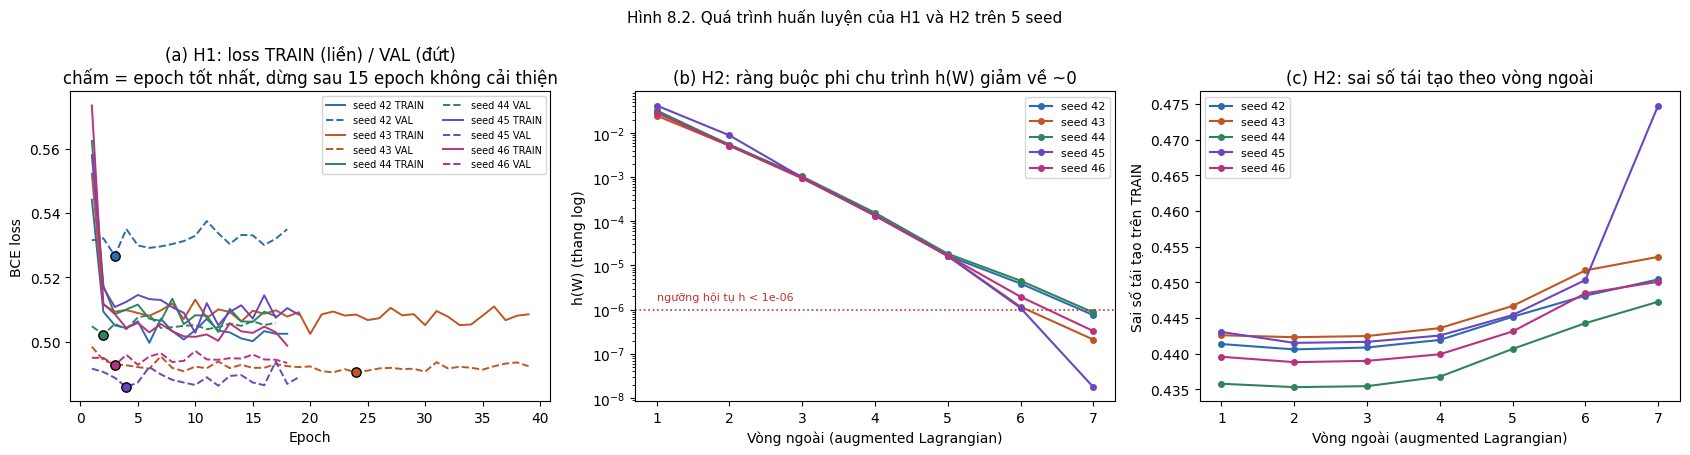

=== H1: số epoch đã chạy và epoch tốt nhất (tối đa 150 epoch, patience 15 ) ===


,Seed,Epoch_tốt_nhất,Số_epoch_đã_chạy,BCE_VAL_tốt_nhất,H2_số_vòng_ngoài,H2_h(W)_cuối
0,42,3,18,0.5267,7,7.5e-07
1,43,24,39,0.4904,7,2.1e-07
2,44,2,17,0.5021,7,8.6e-07
3,45,4,19,0.4858,7,1.8e-08
4,46,3,18,0.4926,7,3.3e-07


=== BẢNG 8.E2: AUROC / ACCURACY / LOG-LOSS TRÊN TRAIN, VAL, TEST (trung bình ± độ lệch chuẩn, 5 seed) ===


,Model,AUROC_TRAIN,AUROC_VAL,AUROC_TEST,Accuracy_TRAIN,Accuracy_VAL,Accuracy_TEST,LogLoss_TRAIN,LogLoss_VAL,LogLoss_TEST,AUROC_gap_TRAIN−TEST
0,B0,0.8020 ± 0.0025,0.7999 ± 0.0097,0.7996 ± 0.0119,0.7389 ± 0.0014,0.7423 ± 0.0082,0.7442 ± 0.0059,0.4974 ± 0.0033,0.5024 ± 0.0175,0.4995 ± 0.0175,+0.0024
1,H1,0.8014 ± 0.0027,0.8004 ± 0.0097,0.8012 ± 0.0130,0.7381 ± 0.0022,0.7419 ± 0.0082,0.7365 ± 0.0128,0.4996 ± 0.0035,0.4995 ± 0.0163,0.4987 ± 0.0163,+0.0002
2,H2,0.8134 ± 0.0047,0.8045 ± 0.0091,0.8016 ± 0.0144,0.7514 ± 0.0067,0.7522 ± 0.0167,0.7508 ± 0.0198,0.4872 ± 0.0044,0.5071 ± 0.0138,0.5133 ± 0.0112,+0.0118


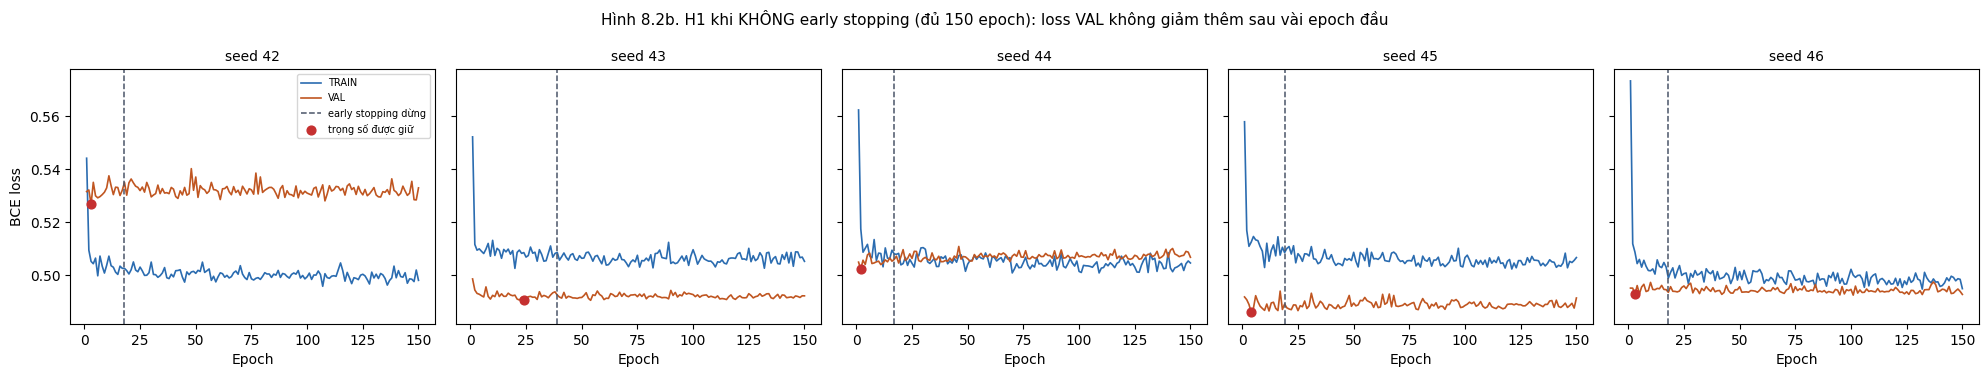

=== BẢNG 8.E2b: H1 CÓ / KHÔNG EARLY STOPPING (từng seed) ===


,Seed,Bản H1,Epoch_đã_chạy,Trọng_số_lấy_ở_epoch,AUROC_TRAIN,LogLoss_TRAIN,AUROC_VAL,LogLoss_VAL,AUROC_TEST,LogLoss_TEST,ATE_TEST,Checkpoint
0,42,Có early stopping,18,3,0.8023,0.4959,0.7870,0.5267,0.8105,0.4854,0.2453,h1_seed42_early_stop.pt
1,42,Không early stopping,150,150,0.8029,0.4955,0.7872,0.5329,0.8072,0.4897,0.2708,h1_seed42_no_early_stop.pt
2,43,Có early stopping,39,24,0.7993,0.5018,0.8029,0.4904,0.8086,0.4943,0.2389,h1_seed43_early_stop.pt
3,43,Không early stopping,150,150,0.7993,0.5020,0.8028,0.4920,0.8086,0.4942,0.2382,h1_seed43_no_early_stop.pt
4,44,Có early stopping,17,2,0.7990,0.5029,0.8001,0.5021,0.8124,0.4885,0.2175,h1_seed44_early_stop.pt
5,44,Không early stopping,150,150,0.8005,0.4988,0.7990,0.5066,0.8069,0.4924,0.2209,h1_seed44_no_early_stop.pt
6,45,Có early stopping,19,4,0.8008,0.5017,0.8139,0.4858,0.7905,0.4991,0.2422,h1_seed45_early_stop.pt
7,45,Không early stopping,150,150,0.8010,0.5012,0.8138,0.4912,0.7905,0.5028,0.2343,h1_seed45_no_early_stop.pt
8,46,Có early stopping,18,3,0.8056,0.4958,0.7981,0.4926,0.7839,0.5264,0.2433,h1_seed46_early_stop.pt
9,46,Không early stopping,150,150,0.8058,0.4943,0.7980,0.4925,0.7837,0.5281,0.2224,h1_seed46_no_early_stop.pt


=== Trung bình ± độ lệch chuẩn trên 5 seed ===


AUROC_TRAIN         LogLoss_TRAIN         AUROC_VAL  \
                            mean     std          mean     std      mean   
Bản H1                                                                     
Có early stopping         0.8014  0.0027        0.4996  0.0035    0.8004   
Không early stopping      0.8019  0.0025        0.4984  0.0034    0.8001   

                             LogLoss_VAL         AUROC_TEST          \
                         std        mean     std       mean     std   
Bản H1                                                                
Có early stopping     0.0097      0.4995  0.0163     0.8012  0.0130   
Không early stopping  0.0096      0.5030  0.0179     0.7994  0.0115   

                     LogLoss_TEST         ATE_TEST          
                             mean     std     mean     std  
Bản H1                                                      
Có early stopping          0.4987  0.0163   0.2374  0.0114  
Không early stopping       0.5014  0.0157   0.2373  0.0202

In [12]:
# ==============================================================================
# Mục 8.E2: Quá trình huấn luyện và kiểm tra overfit (Hình 8.2, Bảng 8.E2)
# ==============================================================================
def ve_qua_trinh_huan_luyen(run_artifacts: Dict[int, Dict[str, Any]], cfg: Config, duong_dan_luu: Path) -> None:
    """
    Hàm này để làm gì: Vẽ quá trình huấn luyện của hai mô hình có tối ưu lặp:
    (a) H1 — BCE trên TRAIN và VALIDATION theo từng epoch, đánh dấu epoch tốt nhất (early stopping);
    (b) H2 — ràng buộc phi chu trình h(W) theo từng vòng ngoài của augmented Lagrangian (thang log);
    (c) H2 — sai số tái tạo (MSE/2) trên TRAIN theo từng vòng ngoài.
    B0 không có epoch (CPD BDeu là đếm tần suất có làm mịn) nên không có đường cong.

    Nhận vào:
        run_artifacts (Dict[int, Dict[str, Any]]): Kết quả 5 run ghép cặp của mục 8.E.
        cfg (Config): Cấu hình chung (patience, ngưỡng hội tụ h).
        duong_dan_luu (Path): Đường dẫn lưu PNG.
    """
    mau = dict(zip(cfg.seeds, ['#2b6cb0', '#c05621', '#2f855a', '#6b46c1', '#b83280']))
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 4.6))
    for seed, art in run_artifacts.items():
        log = art['H1_log']
        ep = np.arange(1, len(log['train_loss']) + 1)
        ax1.plot(ep, log['train_loss'], color=mau[seed], lw=1.4, label=f'seed {seed} TRAIN')
        ax1.plot(ep, log['val_loss'], color=mau[seed], lw=1.4, ls='--', label=f'seed {seed} VAL')
        ax1.scatter([log['best_epoch'] + 1], [log['best_val_bce']], color=mau[seed], s=45, zorder=5, edgecolor='black')
        res = art['H2_res']
        vong = np.arange(1, len(res['h_history']) + 1)
        ax2.semilogy(vong, res['h_history'], marker='o', ms=4, color=mau[seed], label=f'seed {seed}')
        ax3.plot(vong, res['recon_history'], marker='o', ms=4, color=mau[seed], label=f'seed {seed}')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('BCE loss')
    ax1.set_title(f'(a) H1: loss TRAIN (liền) / VAL (đứt)\nchấm = epoch tốt nhất, dừng sau {cfg.h1_patience} epoch không cải thiện')
    ax1.legend(fontsize=7, ncol=2)
    ax2.axhline(cfg.h2_h_tol, color='#c53030', ls=':', lw=1.2)
    ax2.text(1, cfg.h2_h_tol * 1.6, f'ngưỡng hội tụ h < {cfg.h2_h_tol:g}', color='#c53030', fontsize=8)
    ax2.set_xlabel('Vòng ngoài (augmented Lagrangian)')
    ax2.set_ylabel('h(W) (thang log)')
    ax2.set_title('(b) H2: ràng buộc phi chu trình h(W) giảm về ~0')
    ax2.legend(fontsize=8)
    ax3.set_xlabel('Vòng ngoài (augmented Lagrangian)')
    ax3.set_ylabel('Sai số tái tạo trên TRAIN')
    ax3.set_title('(c) H2: sai số tái tạo theo vòng ngoài')
    ax3.legend(fontsize=8)
    fig.suptitle('Hình 8.2. Quá trình huấn luyện của H1 và H2 trên 5 seed', fontsize=11)
    fig.tight_layout()
    fig.savefig(duong_dan_luu, dpi=150, bbox_inches='tight')
    plt.show()


def bang_overfit_theo_tap(run_artifacts: Dict[int, Dict[str, Any]], cfg: Config) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """
    Hàm này để làm gì: Tính AUROC, Accuracy (ngưỡng 0.5) và log-loss của B0, H1, H2 trên cả TRAIN, VALIDATION
    và TEST của từng seed, dùng đúng hàm dự báo P(Y=1 | T_obs, Pa(Y)) của Table A. Chênh lệch TRAIN − TEST lớn
    là dấu hiệu overfit. Hàm này chỉ ĐỌC mô hình đã huấn luyện, không chọn hay chỉnh gì theo TEST.

    Nhận vào:
        run_artifacts (Dict[int, Dict[str, Any]]): Kết quả 5 run ghép cặp (có mô hình và dữ liệu từng tập).
        cfg (Config): Cấu hình chung.

    Trả ra:
        Tuple[pd.DataFrame, pd.DataFrame]: (bảng chi tiết từng seed, bảng tóm tắt trung bình ± độ lệch chuẩn).
    """
    dong: List[Dict[str, Any]] = []
    for seed, art in run_artifacts.items():
        for ten_mo_hinh, mo_hinh in art['models'].items():
            for ten_tap, df in art['data'].items():
                _, _, p = query_model_effects(mo_hinh, df, cfg)
                y = df[cfg.outcome].values.astype(int)
                p = np.clip(p, 1e-6, 1 - 1e-6)
                dong.append({'Model': ten_mo_hinh, 'Seed': seed, 'Tập': ten_tap,
                             'AUROC': metrics.roc_auc_score(y, p),
                             'Accuracy': metrics.accuracy_score(y, (p >= 0.5).astype(int)),
                             'LogLoss': metrics.log_loss(y, p)})
    chi_tiet = pd.DataFrame(dong)
    tom_tat = []
    for ten_mo_hinh in ['B0', 'H1', 'H2']:
        d = chi_tiet[chi_tiet['Model'] == ten_mo_hinh]
        hang: Dict[str, Any] = {'Model': ten_mo_hinh}
        for chi_so in ['AUROC', 'Accuracy', 'LogLoss']:
            for ten_tap in ['TRAIN', 'VAL', 'TEST']:
                x = d[d['Tập'] == ten_tap][chi_so]
                hang[f'{chi_so}_{ten_tap}'] = f'{x.mean():.4f} ± {x.std():.4f}'
        gap = (d[d['Tập'] == 'TRAIN'].set_index('Seed')['AUROC'] - d[d['Tập'] == 'TEST'].set_index('Seed')['AUROC'])
        hang['AUROC_gap_TRAIN−TEST'] = f'{gap.mean():+.4f}'
        tom_tat.append(hang)
    return chi_tiet, pd.DataFrame(tom_tat)


ve_qua_trinh_huan_luyen(run_artifacts, GLOBAL_CONFIG, Path(GLOBAL_CONFIG.graphs_dir) / 'training_curves_h1_h2.png')

print('=== H1: số epoch đã chạy và epoch tốt nhất (tối đa', GLOBAL_CONFIG.h1_epochs, 'epoch, patience',
      GLOBAL_CONFIG.h1_patience, ') ===')
display(pd.DataFrame([{'Seed': s, 'Epoch_tốt_nhất': a['H1_log']['best_epoch'] + 1, 'Số_epoch_đã_chạy': a['H1_log']['epochs_run'],
                       'BCE_VAL_tốt_nhất': round(a['H1_log']['best_val_bce'], 4),
                       'H2_số_vòng_ngoài': a['H2_res']['outer_iters'], 'H2_h(W)_cuối': f"{a['H2_res']['h_final']:.1e}"}
                      for s, a in run_artifacts.items()]))

bang_overfit_chi_tiet, bang_overfit = bang_overfit_theo_tap(run_artifacts, GLOBAL_CONFIG)
print('=== BẢNG 8.E2: AUROC / ACCURACY / LOG-LOSS TRÊN TRAIN, VAL, TEST (trung bình ± độ lệch chuẩn, 5 seed) ===')
display(bang_overfit)
bang_overfit_chi_tiet.round(4).to_csv(Path(GLOBAL_CONFIG.tables_dir) / 'Table_Overfit_Train_Val_Test.csv', index=False)

# ------------------------------------------------------------------------------
# H1 có và không có early stopping — huấn luyện 2 bản, lưu 2 checkpoint riêng
# ------------------------------------------------------------------------------
def so_sanh_early_stopping(run_artifacts: Dict[int, Dict[str, Any]], cfg: Config) -> Tuple[pd.DataFrame, Dict[int, Dict[str, Any]]]:
    """
    Hàm này để làm gì: Với mỗi seed, đặt cạnh nhau hai bản H1 trên cùng DAG B0, cùng TRAIN/VAL và cùng seed:
    (1) có early stopping — chính là H1 dùng trong Tables A–C; (2) không early stopping — chạy đủ cfg.h1_epochs
    và giữ trọng số epoch cuối. Lưu hai checkpoint riêng: h1_seed<s>_early_stop.pt và h1_seed<s>_no_early_stop.pt.
    Trạng thái bộ sinh số ngẫu nhiên được lưu và khôi phục, nên các cell phía sau (refuter, Table C) không đổi.

    Nhận vào:
        run_artifacts (Dict[int, Dict[str, Any]]): Kết quả 5 run ghép cặp của mục 8.E.
        cfg (Config): Cấu hình chung.

    Trả ra:
        Tuple[pd.DataFrame, Dict[int, Dict[str, Any]]]: (bảng so sánh từng seed, nhật ký huấn luyện bản không dừng sớm).
    """
    trang_thai = (random.getstate(), np.random.get_state(), torch.get_rng_state())
    dong: List[Dict[str, Any]] = []
    nhat_ky_khong_dung: Dict[int, Dict[str, Any]] = {}
    for seed, art in run_artifacts.items():
        d = art['data']
        b0 = art['models']['B0']
        parents = list(b0.get_cpds(cfg.outcome).variables[1:])
        p_es = save_h1_checkpoint(art['H1_mlp'], art['H1_log'], seed, cfg, hau_to='_early_stop')
        mlp_no, log_no = train_h1_mlp(d['TRAIN'], d['VAL'], parents, cfg, seed=seed, dung_som=False)
        p_no = save_h1_checkpoint(mlp_no, log_no, seed, cfg, hau_to='_no_early_stop')
        nhat_ky_khong_dung[seed] = log_no
        ban = [('Có early stopping', art['models']['H1'], art['H1_log'], p_es),
               ('Không early stopping', build_h1_bayesian_network(b0, mlp_no, cfg), log_no, p_no)]
        for ten, bn, log, duong_dan in ban:
            q0, q1, _ = query_model_effects(bn, d['TEST'], cfg)
            hang: Dict[str, Any] = {'Seed': seed, 'Bản H1': ten, 'Epoch_đã_chạy': log['epochs_run'],
                                    'Trọng_số_lấy_ở_epoch': (log['best_epoch'] + 1) if log['early_stopping'] else log['epochs_run']}
            for ten_tap in ['TRAIN', 'VAL', 'TEST']:
                _, _, p = query_model_effects(bn, d[ten_tap], cfg)
                y = d[ten_tap][cfg.outcome].values.astype(int)
                p = np.clip(p, 1e-6, 1 - 1e-6)
                hang[f'AUROC_{ten_tap}'] = metrics.roc_auc_score(y, p)
                hang[f'LogLoss_{ten_tap}'] = metrics.log_loss(y, p)
            hang['ATE_TEST'] = float(np.mean(q1) - np.mean(q0))
            hang['Checkpoint'] = Path(duong_dan).name
            dong.append(hang)
    random.setstate(trang_thai[0])
    np.random.set_state(trang_thai[1])
    torch.set_rng_state(trang_thai[2])
    return pd.DataFrame(dong), nhat_ky_khong_dung


def ve_early_stopping(run_artifacts: Dict[int, Dict[str, Any]], nhat_ky_khong_dung: Dict[int, Dict[str, Any]],
                      duong_dan_luu: Path) -> None:
    """
    Hàm này để làm gì: Vẽ loss TRAIN/VAL của bản H1 KHÔNG early stopping trong đủ 150 epoch, kèm vạch dọc tại epoch
    mà bản CÓ early stopping đã dừng và chấm tại epoch có loss VAL thấp nhất, để thấy vì sao dừng sớm.

    Nhận vào:
        run_artifacts (Dict[int, Dict[str, Any]]): Kết quả 5 run (nhật ký bản có early stopping).
        nhat_ky_khong_dung (Dict[int, Dict[str, Any]]): Nhật ký bản không early stopping.
        duong_dan_luu (Path): Đường dẫn lưu PNG.
    """
    cac_seed = list(nhat_ky_khong_dung.keys())
    fig, axes = plt.subplots(1, len(cac_seed), figsize=(4 * len(cac_seed), 3.8), sharey=True)
    for ax, seed in zip(axes, cac_seed):
        log_no = nhat_ky_khong_dung[seed]
        log_es = run_artifacts[seed]['H1_log']
        ep = np.arange(1, len(log_no['train_loss']) + 1)
        ax.plot(ep, log_no['train_loss'], color='#2b6cb0', lw=1.2, label='TRAIN')
        ax.plot(ep, log_no['val_loss'], color='#c05621', lw=1.2, label='VAL')
        ax.axvline(log_es['epochs_run'], color='#4a5568', ls='--', lw=1.1, label='early stopping dừng')
        ax.scatter([log_es['best_epoch'] + 1], [log_es['best_val_bce']], color='#c53030', s=40, zorder=5,
                   label='trọng số được giữ')
        ax.set_title(f'seed {seed}', fontsize=10)
        ax.set_xlabel('Epoch')
    axes[0].set_ylabel('BCE loss')
    axes[0].legend(fontsize=7)
    fig.suptitle('Hình 8.2b. H1 khi KHÔNG early stopping (đủ 150 epoch): loss VAL không giảm thêm sau vài epoch đầu', fontsize=11)
    fig.tight_layout()
    fig.savefig(duong_dan_luu, dpi=150, bbox_inches='tight')
    plt.show()


bang_es, nhat_ky_khong_dung = so_sanh_early_stopping(run_artifacts, GLOBAL_CONFIG)
ve_early_stopping(run_artifacts, nhat_ky_khong_dung, Path(GLOBAL_CONFIG.graphs_dir) / 'h1_early_stopping_vs_full.png')
print('=== BẢNG 8.E2b: H1 CÓ / KHÔNG EARLY STOPPING (từng seed) ===')
display(bang_es.round(4))
tom_tat_es = bang_es.groupby('Bản H1')[[c for c in bang_es.columns if c.startswith(('AUROC', 'LogLoss', 'ATE'))]].agg(['mean', 'std']).round(4)
print('=== Trung bình ± độ lệch chuẩn trên 5 seed ===')
display(tom_tat_es)
bang_es.round(4).to_csv(Path(GLOBAL_CONFIG.tables_dir) / 'Table_H1_Early_Stopping.csv', index=False)


In [13]:
# ==============================================================================
# Mục 8.E: Xuất Table A & Table B
# ==============================================================================
df_pred_raw = pd.DataFrame(prediction_results)
df_interv_raw = pd.DataFrame(intervention_results)

# Hiệu có dấu theo cặp so với B0 trong CÙNG seed (Slide 68, 74)
for metric in ['AUROC', 'Macro_F1', 'Brier_Score']:
    b0_map = df_pred_raw[df_pred_raw['Model'] == 'B0'].set_index('Seed')[metric]
    df_pred_raw[f'Delta_{metric}_vs_B0'] = df_pred_raw[metric] - df_pred_raw['Seed'].map(b0_map)
b0_ate = df_interv_raw[df_interv_raw['Model'] == 'B0'].set_index('Seed')['ATE']
df_interv_raw['Delta_ATE_vs_B0'] = df_interv_raw['ATE'] - df_interv_raw['Seed'].map(b0_ate)


def mean_std(s: pd.Series, fmt: str = '.4f') -> str:
    return f"{s.mean():{fmt}} ± {s.std():{fmt.replace('+', '')}}"


summary_rows_a = []
for m in ['B0', 'H1', 'H2']:
    sub = df_pred_raw[df_pred_raw['Model'] == m]
    summary_rows_a.append({
        'Model': f'{m} (Mean ± Std)', 'Seed': 'Pooled 5 Runs', 'Graph': 'per-seed (see rows)',
        'Test_Size': int(sub['Test_Size'].iloc[0]), 'Test_Positive_Rate': f"{sub['Test_Positive_Rate'].mean():.4f}",
        **{c: mean_std(sub[c]) for c in ['AUROC', 'Macro_F1', 'Brier_Score', 'Log_Loss', 'Precision', 'Recall']},
        'F1_Threshold_from_Val': mean_std(sub['F1_Threshold_from_Val'], '.2f'),
        **{f'Delta_{c}_vs_B0': (mean_std(sub[f'Delta_{c}_vs_B0'], '+.4f') if m != 'B0' else '---')
           for c in ['AUROC', 'Macro_F1', 'Brier_Score']},
        'Fit_Time_s': f"{sub['Fit_Time_s'].mean():.2f}s", 'Query_Time_s': f"{sub['Query_Time_s'].mean():.4f}s",
    })
df_table_a = pd.concat([df_pred_raw, pd.DataFrame(summary_rows_a)], ignore_index=True)
df_table_a['Hardware'] = HARDWARE
df_table_a.to_csv(Path(GLOBAL_CONFIG.tables_dir) / 'Table_A_Prediction.csv', index=False)

summary_rows_b = []
for m in ['B0', 'H1', 'H2']:
    sub = df_interv_raw[df_interv_raw['Model'] == m]
    summary_rows_b.append({
        'Model': f'{m} (Mean ± Std)', 'Seed': 'Pooled 5 Runs', 'Reference_Cohort': 'C_test per seed',
        'Cohort_Size': int(sub['Cohort_Size'].iloc[0]), 'Contrast': 'do(T=1) vs do(T=0)',
        'Risk_do_T0': mean_std(sub['Risk_do_T0']), 'Risk_do_T1': mean_std(sub['Risk_do_T1']),
        'ATE': mean_std(sub['ATE'], '+.4f'),
        'CI_95_Low': f"{sub['CI_95_Low'].mean():+.4f}", 'CI_95_High': f"{sub['CI_95_High'].mean():+.4f}",
        'CI_Method': CI_METHOD + ' (mean of per-seed bounds)', 'Formula': sub['Formula'].iloc[0],
        'Adjustment_Set': ' / '.join(sorted(sub['Adjustment_Set'].unique())),
        'DoWhy_Identification': ' / '.join(sorted(sub['DoWhy_Identification'].unique())),
        'DoWhy_Backdoor_Set': ' / '.join(sorted(sub['DoWhy_Backdoor_Set'].unique())),
        'Overlap_Status': ' / '.join(sorted(sub['Overlap_Status'].unique())),
        'Unsupported_Test_Profiles_pct': f"{sub['Unsupported_Test_Profiles_pct'].mean():.2f}",
        'Delta_ATE_vs_B0': (mean_std(sub['Delta_ATE_vs_B0'], '+.4f') if m != 'B0' else '---'),
    })
df_table_b = pd.concat([df_interv_raw, pd.DataFrame(summary_rows_b)], ignore_index=True)
df_table_b.to_csv(Path(GLOBAL_CONFIG.tables_dir) / 'Table_B_Intervention.csv', index=False)
print('[Xuất bản] Table A, Table B đã lưu trong', GLOBAL_CONFIG.tables_dir)


[Xuất bản] Table A, Table B đã lưu trong artifacts_rang_buoc_z/tables


<a id='s8-f'></a>
### 8.F. Refuter và chi phí tính toán — Table C (Slide 70–71, 75)
#### 8.F.1. Kiểm định độ bền vững phản bác (Refutation Protocol)
Theo quy định chuẩn hóa tại **Slide 70–71 & 75**, chúng ta tích hợp thư viện `DoWhy` để thực thi **2 bài kiểm tra bác bỏ bắt buộc**:
1. **Placebo Treatment Refuter:**
   * Thay thế biến can thiệp $T$ bằng một biến giả ngẫu nhiên (hoán vị nhãn $T$).
   * **Kỳ vọng:** Hiệu ứng nhân quả mới phải triệt tiêu về gần bằng 0 ($p > 0.05$). Nếu hiệu ứng vẫn còn lớn, mô hình đã bị rò rỉ hoặc tồn tại mối quan hệ giả mạo.
2. **Data Subset Refuter:**
   * Ước lượng lại hiệu ứng can thiệp trên tập con 80% dữ liệu lấy mẫu ngẫu nhiên.
   * **Kỳ vọng:** Hiệu ứng ATE mới phải ổn định và không biến động quá mức so với ước lượng ban đầu.
3. **Đối tượng được kiểm định (Slide 70–71):** refuter DoWhy chạy trên **DAG của B0 và DAG của H2** với ước lượng hỗ trợ `backdoor.linear_regression`, nên chúng kiểm tra *đồ thị + ước lượng tuyến tính*, không kiểm tra trực tiếp CPD BDeu. Với **H1 nơ-ron**, refuter tuyến tính không áp dụng được, nên nhóm cài đặt và ghi nhãn riêng một **kiểm định huấn luyện lại**: hoán vị $T$ rồi huấn luyện lại MLP (placebo), và huấn luyện lại trên 80% TRAIN (subset). Vượt qua refuter **không** chứng minh DAG đúng hay không có nhiễu ẩn.
4. **Độ tản mạn hiệu ứng (Paired Effect Spread):**
   * Đo lường tính ổn định thuật toán qua công thức: $\text{Spread} = \text{Max}(\text{ATE}) - \text{Min}(\text{ATE})$ qua 5 hạt giống.


In [14]:
# ==============================================================================
# Mục 8.F: Refuter & Table C
# ==============================================================================
def dowhy_refute_on_graph(dag: nx.DiGraph, df: pd.DataFrame, cfg: Config, seed: int) -> Dict[str, Any]:
    """
    Refuter DoWhy (Slide 69-70) trên ĐÚNG DAG của mô hình, ước lượng hỗ trợ: backdoor.linear_regression.
    Kết quả này kiểm tra (đồ thị + ước lượng tuyến tính), KHÔNG kiểm tra trực tiếp CPD BDeu hay mạng nơ-ron.
    """
    # Đại ý: ước lượng ATE bằng hồi quy tuyến tính trên sơ đồ, rồi chạy 2 refuter, mỗi loại 30 lần:
    #   placebo: xáo T ngẫu nhiên, ATE phải về gần 0; subset: lấy 80% dữ liệu, ATE phải gần như cũ.
    cm = CausalModel(data=df[list(cfg.all_nodes)], treatment=cfg.treatment, outcome=cfg.outcome, graph=dag)
    estimand = cm.identify_effect(proceed_when_unidentifiable=False)
    est = cm.estimate_effect(estimand, method_name='backdoor.linear_regression', test_significance=False)
    np.random.seed(seed)
    plc = cm.refute_estimate(estimand, est, method_name='placebo_treatment_refuter', placebo_type='permute',
                             num_simulations=cfg.placebo_simulations, random_state=seed)
    np.random.seed(seed)
    sub = cm.refute_estimate(estimand, est, method_name='data_subset_refuter', subset_fraction=cfg.subset_fraction,
                             num_simulations=cfg.placebo_simulations, random_state=seed)
    return {'original': float(est.value), 'placebo': float(plc.new_effect), 'subset': float(sub.new_effect),
            'backdoor': sorted(estimand.get_backdoor_variables())}


def h1_retraining_refuter(b0_model: DiscreteBayesianNetwork, train_df: pd.DataFrame, val_df: pd.DataFrame,
                          test_df: pd.DataFrame, cfg: Config, seed: int) -> Dict[str, float]:
    """
    Kiểm định tương tự cho H1 (Slide 70-71: refuter tuyến tính KHÔNG tự động kiểm tra H1 nơ-ron):
    - placebo: hoán vị T trong TRAIN và VALIDATION, huấn luyện lại MLP, tính ATE trên C_test (kỳ vọng ~ 0);
    - subset: huấn luyện lại MLP trên 80% TRAIN, tính ATE trên C_test (kỳ vọng gần ATE gốc).
    """
    # Đại ý: H1 là mạng nơ-ron nên DoWhy không kiểm được; tự làm 2 phép thử tương tự bằng cách huấn luyện lại MLP.
    # Biến chính: plc = ATE khi T bị xáo (kỳ vọng ~0); sub = ATE khi chỉ dùng 80% TRAIN (kỳ vọng gần ATE gốc).
    parents = list(b0_model.get_cpds('Y').variables[1:])
    rng = np.random.default_rng(seed)
    plc, sub = [], []
    for k in range(cfg.h1_refute_sims):
        tr_p, va_p = train_df.copy(), val_df.copy()
        tr_p['T'] = rng.permutation(tr_p['T'].values)
        va_p['T'] = rng.permutation(va_p['T'].values)
        m_p, _ = train_h1_mlp(tr_p, va_p, parents, cfg, seed=seed + 100 + k)
        q0, q1, _ = query_model_effects(build_h1_bayesian_network(b0_model, m_p, cfg), test_df, cfg)
        plc.append(float(np.mean(q1) - np.mean(q0)))
        idx = rng.choice(len(train_df), size=int(cfg.subset_fraction * len(train_df)), replace=False)
        m_s, _ = train_h1_mlp(train_df.iloc[idx].reset_index(drop=True), val_df, parents, cfg, seed=seed + 200 + k)
        q0, q1, _ = query_model_effects(build_h1_bayesian_network(b0_model, m_s, cfg), test_df, cfg)
        sub.append(float(np.mean(q1) - np.mean(q0)))
    return {'placebo': float(np.mean(plc)), 'subset': float(np.mean(sub))}


# (1) Lấy dữ liệu và sơ đồ B0, H2 của seed 42 (seed đầu tiên).
ref_seed = 42
split = CACHED_SPLITS[ref_seed]
tr42 = PRIMARY_DF.iloc[split['train_indices']].reset_index(drop=True)
va42 = PRIMARY_DF.iloc[split['val_indices']].reset_index(drop=True)
te42 = PRIMARY_DF.iloc[split['test_indices']].reset_index(drop=True)
b0_dag42, _, _ = learn_b0_dag(tr42, va42, GLOBAL_CONFIG)
b0_bn42 = fit_bn_on_dag(tr42, b0_dag42, GLOBAL_CONFIG)
h2_dag42, _, _ = select_h2_graph(run_artifacts[ref_seed]['H2_res'], tr42, va42, GLOBAL_CONFIG)

# (2) Chạy refuter cho ba mô hình.
print('Đang chạy refuter DoWhy trên DAG B0 và DAG H2 (seed 42, TRAIN)...')
ref_b0 = dowhy_refute_on_graph(b0_dag42, tr42, GLOBAL_CONFIG, ref_seed)
ref_h2 = dowhy_refute_on_graph(h2_dag42, tr42, GLOBAL_CONFIG, ref_seed)
print('Đang chạy kiểm định huấn luyện lại cho H1 (placebo + subset)...')
ref_h1 = h1_retraining_refuter(b0_bn42, tr42, va42, te42, GLOBAL_CONFIG, ref_seed)
h1_orig = float(df_interv_raw[(df_interv_raw['Model'] == 'H1') & (df_interv_raw['Seed'] == ref_seed)]['ATE'].iloc[0])

# (3) Gom kết quả: Original = ATE gốc, Placebo = ATE khi xáo T, Subset = ATE trên 80% dữ liệu.
refuter_map = {
    'B0': {'Refuter_Target': f"DoWhy LR on B0 DAG, backdoor {{{', '.join(ref_b0['backdoor'])}}}",
           'Original': ref_b0['original'], 'Placebo': ref_b0['placebo'], 'Subset': ref_b0['subset'],
           'Sims': GLOBAL_CONFIG.placebo_simulations},
    'H1': {'Refuter_Target': 'Custom retraining of H1 MLP (permuted T / 80% TRAIN), ATE on C_test',
           'Original': h1_orig, 'Placebo': ref_h1['placebo'], 'Subset': ref_h1['subset'],
           'Sims': GLOBAL_CONFIG.h1_refute_sims},
    'H2': {'Refuter_Target': f"DoWhy LR on H2 DAG, backdoor {{{', '.join(ref_h2['backdoor'])}}}",
           'Original': ref_h2['original'], 'Placebo': ref_h2['placebo'], 'Subset': ref_h2['subset'],
           'Sims': GLOBAL_CONFIG.placebo_simulations},
}

# (4) Mỗi mô hình một dòng Table C. Đạt nếu |Placebo| < 0.05 và |Subset - Original| < 0.05;
#     kèm ATE trung bình ± độ lệch qua 5 seed, độ tản max - min, thời gian chạy.
table_c_rows = []
for m in ['B0', 'H1', 'H2']:
    sub_p = df_pred_raw[df_pred_raw['Model'] == m]
    sub_i = df_interv_raw[df_interv_raw['Model'] == m]
    r = refuter_map[m]
    table_c_rows.append({
        'Model': m, 'Refuter_Target': r['Refuter_Target'], 'Refuter_Seed': ref_seed, 'Simulations': r['Sims'],
        'Original_Effect': f"{r['Original']:+.4f}",
        'Placebo_Effect': f"{r['Placebo']:+.4f} (Pass: {abs(r['Placebo']) < 0.05})",
        'Subset_Effect': f"{r['Subset']:+.4f} (Pass: {abs(r['Subset'] - r['Original']) < 0.05})",
        'ATE_Mean_±_Std_5_Runs': mean_std(sub_i['ATE'], '+.4f'),
        'Paired_Spread_Max_Min': f"{sub_i['ATE'].max() - sub_i['ATE'].min():.4f}",
        'Delta_ATE_vs_B0': mean_std(sub_i['Delta_ATE_vs_B0'], '+.4f') if m != 'B0' else '---',
        'Fit_Time_mean_s': f"{sub_p['Fit_Time_s'].mean():.2f}", 'Query_Time_mean_s': f"{sub_p['Query_Time_s'].mean():.4f}",
        'Hardware': HARDWARE,
    })
df_table_c = pd.DataFrame(table_c_rows)
df_table_c.to_csv(Path(GLOBAL_CONFIG.tables_dir) / 'Table_C_Robustness_Cost.csv', index=False)
print('[Xuất bản] Table C đã lưu.')


Đang chạy refuter DoWhy trên DAG B0 và DAG H2 (seed 42, TRAIN)...


             Note: The underlying distribution may not be Normal. We assume that it approaches normal with the increase in sample size.
             Note: The underlying distribution may not be Normal. We assume that it approaches normal with the increase in sample size.
             Note: The underlying distribution may not be Normal. We assume that it approaches normal with the increase in sample size.
             Note: The underlying distribution may not be Normal. We assume that it approaches normal with the increase in sample size.


Đang chạy kiểm định huấn luyện lại cho H1 (placebo + subset)...
[Xuất bản] Table C đã lưu.


### Kết quả Tables A–C với ràng buộc mới
Ba bảng dưới đọc lại từ `artifacts_rang_buoc_z/tables/`, cùng định dạng với bản gốc.

In [15]:
COT_A = ['Model', 'Seed', 'Graph', 'AUROC', 'Macro_F1', 'Brier_Score', 'Log_Loss', 'Delta_AUROC_vs_B0', 'Fit_Time_s']
COT_B = ['Model', 'Seed', 'Risk_do_T0', 'Risk_do_T1', 'ATE', 'CI_95_Low', 'CI_95_High', 'Adjustment_Set',
         'DoWhy_Identification', 'Overlap_Status']
THU_MUC_BANG = Path(GLOBAL_CONFIG.tables_dir)
df_table_a = pd.read_csv(THU_MUC_BANG / 'Table_A_Prediction.csv')
df_table_b = pd.read_csv(THU_MUC_BANG / 'Table_B_Intervention.csv')
df_table_c = pd.read_csv(THU_MUC_BANG / 'Table_C_Robustness_Cost.csv')

with pd.option_context('display.precision', 4, 'display.max_colwidth', 80):
    print('=== TABLE A (ràng buộc mới): DỰ BÁO TRÊN TEST ===')
    display(df_table_a[COT_A])
    print('\n=== TABLE B (ràng buộc mới): CAN THIỆP CHUẨN HÓA TRÊN C_test ===')
    display(df_table_b[COT_B])
    print('\n=== TABLE C (ràng buộc mới): REFUTER & CHI PHÍ ===')
    display(df_table_c.drop(columns=['Hardware']))


=== TABLE A (ràng buộc mới): DỰ BÁO TRÊN TEST ===


,Model,Seed,Graph,AUROC,Macro_F1,Brier_Score,Log_Loss,Delta_AUROC_vs_B0,Fit_Time_s
0,B0,42,B0-HC-K2-s42 (11 edges),0.8072996210192884,0.7371343111638542,0.16053969367307735,0.48605631675351646,0.0,0.5659389495849609
1,H1,42,B0-HC-K2-s42 (11 edges) + neural CPD(Y),0.8104955031393178,0.7371343111638542,0.16034325469473107,0.4853926164909833,0.003195882120029414,1.6361455917358398
2,H2,42,"H2-NOTEARS-MLP-s42 (tau=0.1, 13 edges, h=7.5e-07)",0.8149711522144918,0.7486661747594858,0.15971468417197415,0.5043674360672921,0.007671531195203363,23.784919261932373
3,B0,43,B0-HC-K2-s43 (10 edges),0.8096046156456813,0.7426388888888888,0.16269107015020726,0.49135229544714665,0.0,0.49268150329589844
4,H1,43,B0-HC-K2-s43 (10 edges) + neural CPD(Y),0.808643022795407,0.7426388888888888,0.16300196451295998,0.4942941677063525,-0.0009615928502743065,3.493830680847168
5,H2,43,"H2-NOTEARS-MLP-s43 (tau=0.2, 9 edges, h=2.1e-07)",0.8160741557780417,0.7447971862028173,0.16371397265858625,0.5043772896685816,0.006469540132360341,24.9248309135437
6,B0,44,B0-HC-BDeu-s44 (10 edges),0.8071440692346853,0.7412505501436438,0.16312029517059523,0.49038319652609896,0.0,0.5073509216308594
7,H1,44,B0-HC-BDeu-s44 (10 edges) + neural CPD(Y),0.8123621245545563,0.7412505501436438,0.161522754685257,0.48852096073379186,0.005218055319870962,1.4957916736602783
8,H2,44,"H2-NOTEARS-MLP-s44 (tau=0.1, 14 edges, h=8.6e-07)",0.8023078228406584,0.7332842773097114,0.1699393422985151,0.5205624055892802,-0.004836246394026911,23.897181034088135
9,B0,45,B0-HC-K2-s45 (11 edges),0.7903727586401945,0.7243452849275036,0.16799175932445187,0.5002304733202727,0.0,0.5399739742279053



=== TABLE B (ràng buộc mới): CAN THIỆP CHUẨN HÓA TRÊN C_test ===


,Model,Seed,Risk_do_T0,Risk_do_T1,ATE,CI_95_Low,CI_95_High,Adjustment_Set,DoWhy_Identification,Overlap_Status
0,B0,42,0.5396672419843352,0.7863206769228432,0.246653434938508,0.2394,0.2541,"{Z2, Z3, Z5}",identified (backdoor),full overlap
1,H1,42,0.5418051234557542,0.7870759687292467,0.24527084527349252,0.2373,0.2535,"{Z2, Z3, Z5}",identified (backdoor),full overlap
2,H2,42,0.5435673278340404,0.786345140593709,0.2427778127596686,0.2324,0.2519,"{Z1, Z2, Z3, Z5}",identified (backdoor),7 test profiles lack overlap
3,B0,43,0.5436246180227601,0.7907093955377338,0.2470847775149737,0.2395,0.2546,"{Z2, Z3, Z5}",identified (backdoor),full overlap
4,H1,43,0.5446659619210783,0.7835993833498124,0.23893342142873408,0.2320,0.2456,"{Z2, Z3, Z5}",identified (backdoor),full overlap
5,H2,43,0.5430100040197576,0.7833713543388742,0.24036135031911654,0.2304,0.2502,"{Z1, Z2, Z3, Z5}",identified (backdoor),5 test profiles lack overlap
6,B0,44,0.5411370304434542,0.7795864530660008,0.23844942262254665,0.2309,0.2468,"{Z2, Z3, Z5}",identified (backdoor),full overlap
7,H1,44,0.543303491544286,0.7608327640237611,0.21752927247947507,0.2079,0.2271,"{Z2, Z3, Z5}",identified (backdoor),full overlap
8,H2,44,0.5438996973979654,0.7766038055526977,0.2327041081547323,0.2198,0.2460,"{Z1, Z2, Z3, Z4, Z5}",identified (backdoor),27 test profiles lack overlap
9,B0,45,0.5585456992878847,0.7968992748395836,0.2383535755516989,0.2306,0.2462,"{Z2, Z3, Z5}",identified (backdoor),full overlap



=== TABLE C (ràng buộc mới): REFUTER & CHI PHÍ ===


,Model,Refuter_Target,Refuter_Seed,Simulations,Original_Effect,Placebo_Effect,Subset_Effect,ATE_Mean_±_Std_5_Runs,Paired_Spread_Max_Min,Delta_ATE_vs_B0,Fit_Time_mean_s,Query_Time_mean_s
0,B0,"DoWhy LR on B0 DAG, backdoor {Z3, Z5}",42,30,0.2268,+0.0017 (Pass: True),+0.2238 (Pass: True),+0.2418 ± 0.0046,0.0087,---,0.53,0.0003
1,H1,"Custom retraining of H1 MLP (permuted T / 80% TRAIN), ATE on C_test",42,3,0.2453,+0.0177 (Pass: True),+0.2365 (Pass: True),+0.2374 ± 0.0114,0.0277,-0.0044 ± 0.0106,1.97,0.0002
2,H2,"DoWhy LR on H2 DAG, backdoor {Z1, Z3, Z5}",42,30,0.2279,+0.0016 (Pass: True),+0.2250 (Pass: True),+0.2372 ± 0.0049,0.0112,-0.0046 ± 0.0028,25.03,0.0003


### Đồ thị học được với ràng buộc mới (Hình 8.1)
Mặt nạ (a) giờ có thêm 9 ô cấm bên trong khối $Z$. So với Hình 8.1 bản gốc, không còn cạnh kiểu `Học phí → Tuổi`.

In [16]:
THU_MUC_HINH = Path(GLOBAL_CONFIG.graphs_dir)


def ve_do_thi_co_huong(ax: plt.Axes, cac_canh: List[Tuple[str, str]], vi_tri: Dict[str, Tuple[float, float]],
                       nhan: Dict[str, str], tieu_de: str, canh_do: Set[Tuple[str, str]],
                       canh_net_dut: Optional[Set[Tuple[str, str]]] = None,
                       do_cong: float | Dict[Tuple[str, str], float] = 0.08,
                       kich_thuoc_nut: int = 2600) -> None:
    """
    Hàm này để làm gì: Vẽ một đồ thị có hướng lên trục ax với vị trí nút cố định; tô đỏ các cạnh trong canh_do
    (ví dụ cạnh ngược thời gian) và vẽ nét đứt các cạnh trong canh_net_dut (ví dụ cạnh bị ép thêm/bị cắt).

    Nhận vào:
        ax (plt.Axes): Trục vẽ.
        cac_canh (List[Tuple[str, str]]): Danh sách cạnh (u, v).
        vi_tri (Dict[str, Tuple[float, float]]): Tọa độ từng nút.
        nhan (Dict[str, str]): Nhãn hiển thị của từng nút.
        tieu_de (str): Tiêu đề ô hình.
        canh_do (Set[Tuple[str, str]]): Các cạnh tô đỏ.
        canh_net_dut (Optional[Set[Tuple[str, str]]]): Các cạnh vẽ nét đứt.
        do_cong (float | Dict): Độ cong của cạnh (0 = thẳng); truyền dict {(u, v): độ cong} để cong riêng
            từng cạnh (cạnh không có trong dict vẽ thẳng).
        kich_thuoc_nut (int): Kích thước nút.
    """
    canh_net_dut = canh_net_dut or set()
    g = nx.DiGraph()
    g.add_nodes_from(vi_tri.keys())
    g.add_edges_from(cac_canh)
    nx.draw_networkx_nodes(g, vi_tri, ax=ax, node_size=kich_thuoc_nut, node_color='#edf2f7', edgecolors='#2d3748', linewidths=1.2)
    nx.draw_networkx_labels(g, vi_tri, labels=nhan, ax=ax, font_size=8.5)
    for (u, v) in g.edges():
        mau = '#c53030' if (u, v) in canh_do else '#2d3748'
        kieu = 'dashed' if (u, v) in canh_net_dut else 'solid'
        cong = do_cong.get((u, v), 0.0) if isinstance(do_cong, dict) else do_cong
        nx.draw_networkx_edges(g, vi_tri, edgelist=[(u, v)], ax=ax, edge_color=mau, style=kieu, width=2.0,
                               arrowsize=18, node_size=kich_thuoc_nut, connectionstyle=f'arc3,rad={cong}')
    ax.margins(0.12)
    ax.set_title(tieu_de, fontsize=10)
    ax.axis('off')



=== TÓM TẮT ĐỒ THỊ ĐÃ HỌC VÀ LỰA CHỌN TRÊN VALIDATION (5 SEED) ===


,Seed,B0_score(val),B0_edges,B0_Pa(Y),H2_tau(val),H2_edges,H2_Pa(Y),H2_h(W),H2_converged,H2_T->Y_forced,H2_max|W|_forbidden
0,42,K2,11,"[T, Z2, Z3, Z5]",0.1,13,"[T, Z1, Z2, Z3, Z5]",7.5e-07,True,False,0.0
1,43,K2,10,"[T, Z2, Z3, Z5]",0.2,9,"[T, Z1, Z2, Z3, Z5]",2.1e-07,True,False,0.0
2,44,BDeu,10,"[T, Z2, Z3, Z5]",0.1,14,"[T, Z1, Z2, Z3, Z4, Z5]",8.6e-07,True,False,0.0
3,45,K2,11,"[T, Z2, Z3, Z5]",0.1,15,"[T, Z1, Z2, Z3, Z4, Z5]",1.8e-08,True,False,0.0
4,46,K2,11,"[T, Z2, Z3, Z5]",0.2,8,"[T, Z2, Z3, Z5]",3.3e-07,True,False,0.0


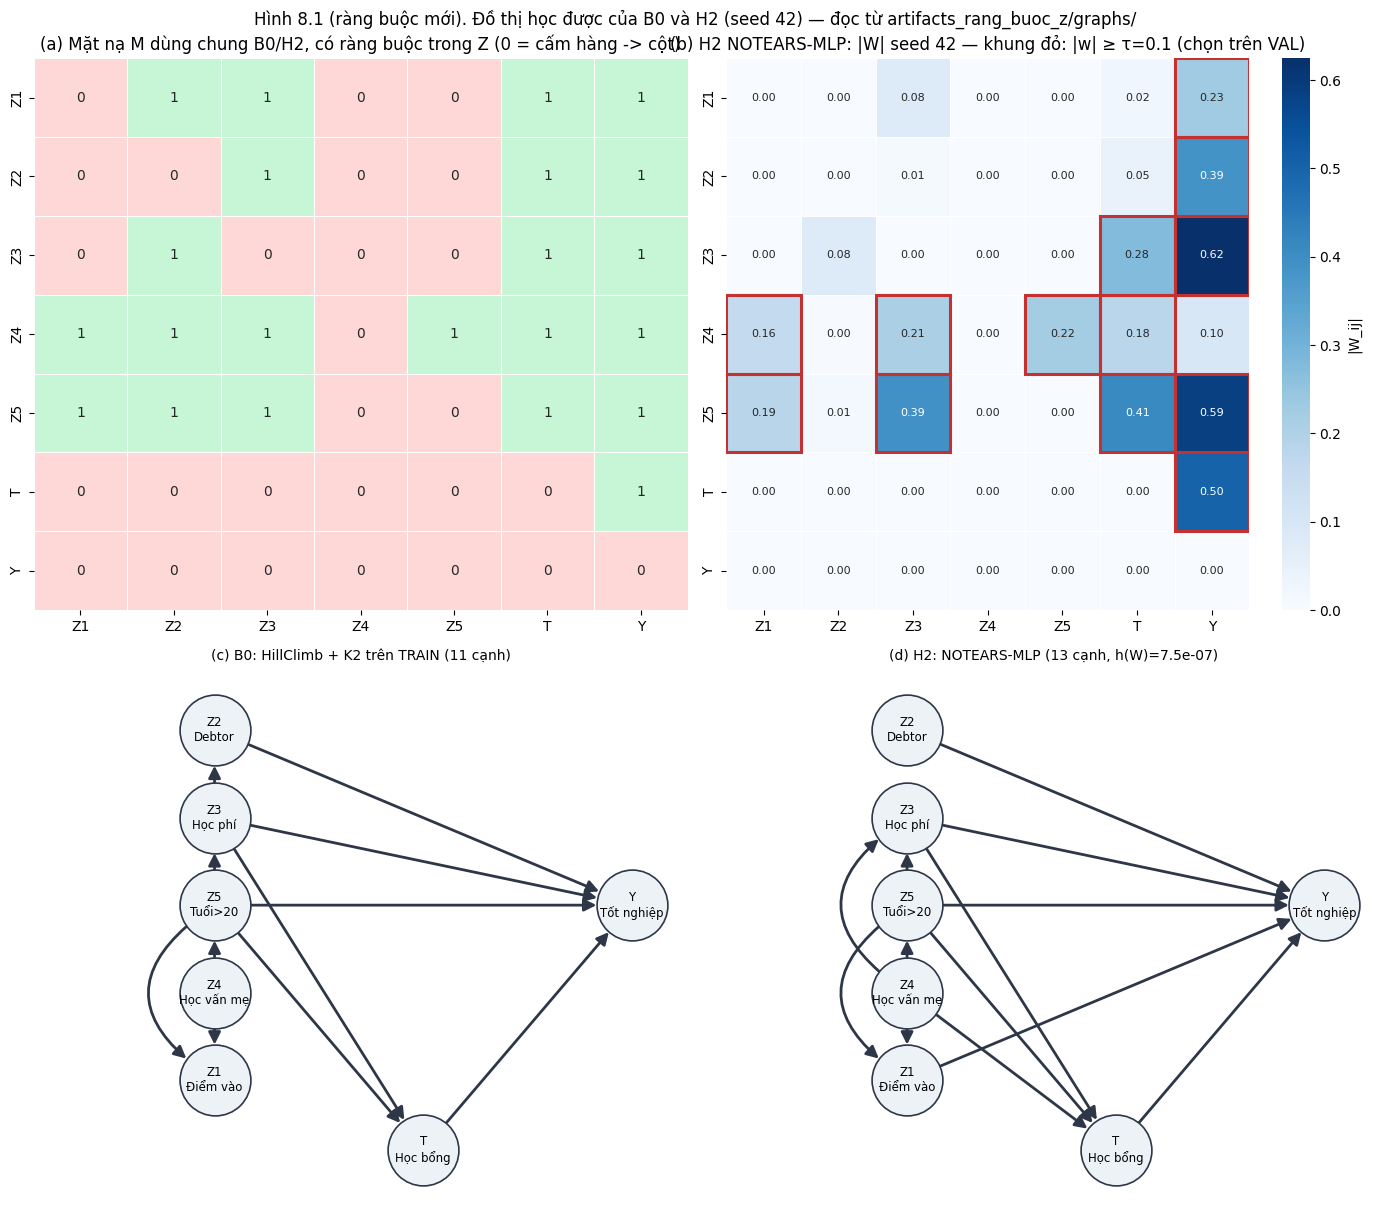

In [17]:
NUT_7: Tuple[str, ...] = ('Z1', 'Z2', 'Z3', 'Z4', 'Z5', 'T', 'Y')
NHAN_7 = {'Z1': 'Z1\nĐiểm vào', 'Z2': 'Z2\nDebtor', 'Z3': 'Z3\nHọc phí', 'Z4': 'Z4\nHọc vấn mẹ',
          'Z5': 'Z5\nTuổi>20', 'T': 'T\nHọc bổng', 'Y': 'Y\nTốt nghiệp'}
# Bố cục giống Hình 6.1: Z xếp cột trái, T hạ xuống hàng dưới, Y bên phải -> cạnh Z -> Y không xuyên qua T.
# Thứ tự cột Z2, Z3, Z5, Z4, Z1 theo chuỗi cạnh Z -> Z mà B0 học được, để phần lớn cạnh Z -> Z nối hai nút kề nhau.
VI_TRI_7 = {'Z2': (0, 4), 'Z3': (0, 2), 'Z5': (0, 0), 'Z4': (0, -2), 'Z1': (0, -4), 'T': (3.0, -5.6), 'Y': (6.0, 0)}


def do_cong_canh_z_z(cac_canh: List[Tuple[str, str]], vi_tri: Dict[str, Tuple[float, float]],
                     muc_cong: float = 3.0) -> Dict[Tuple[str, str], float]:
    """
    Hàm này để làm gì: Gán độ cong cho các cạnh nối hai biến Z cùng cột. Cạnh nối hai nút kề nhau vẽ thẳng;
    cạnh nối hai nút cách xa vòng ra phía bên trái (không chạy xuyên qua các nút Z nằm giữa), cạnh càng dài
    thì vòng càng rộng nên không đè lên nhau.

    Nhận vào:
        cac_canh (List[Tuple[str, str]]): Danh sách cạnh (u, v).
        vi_tri (Dict[str, Tuple[float, float]]): Tọa độ từng nút.
        muc_cong (float): Khoảng vòng ra bên trái (theo đơn vị trục x) của cạnh ngắn nhất cần cong.

    Trả ra:
        Dict[Tuple[str, str], float]: Độ cong của từng cạnh Z -> Z (cạnh khác vẽ thẳng).
    """
    cong: Dict[Tuple[str, str], float] = {}
    for (u, v) in cac_canh:
        if u.startswith('Z') and v.startswith('Z'):
            dy = vi_tri[v][1] - vi_tri[u][1]
            so_buoc = round(abs(dy) / 2)
            if so_buoc <= 1:
                continue
            rad = (muc_cong + 0.7 * (so_buoc - 2)) / abs(dy)
            cong[(u, v)] = rad if dy < 0 else -rad
    return cong


def doc_do_thi_da_luu(ten: str) -> Dict[str, object]:
    """
    Hàm này để làm gì: Đọc file JSON đồ thị do pipeline mục 8 vừa lưu (artifacts/graphs/<ten>.json).

    Nhận vào:
        ten (str): Tên file không kèm đuôi, ví dụ 'b0_dag_seed42'.

    Trả ra:
        Dict[str, object]: Danh sách nút, cạnh và thông tin chọn mô hình.
    """
    with open(THU_MUC_HINH / f'{ten}.json', 'r', encoding='utf-8') as tep:
        return json.load(tep)


def mat_na_thoi_gian(cac_nut: Tuple[str, ...]) -> np.ndarray:
    """
    Hàm này để làm gì: Tạo mặt nạ M (0 = cấm cạnh hàng -> cột): cấm tự nối, cấm Y -> (T, Z), cấm T -> Z.

    Nhận vào:
        cac_nut (Tuple[str, ...]): Thứ tự nút.

    Trả ra:
        np.ndarray: Ma trận mặt nạ.
    """
    m = np.ones((len(cac_nut), len(cac_nut)))
    np.fill_diagonal(m, 0)
    iy, it = cac_nut.index('Y'), cac_nut.index('T')
    m[iy, :] = 0
    for k, ten in enumerate(cac_nut):
        if ten.startswith('Z'):
            m[it, k] = 0
    return m


def bang_tom_tat_do_thi(cac_seed: Tuple[int, ...]) -> pd.DataFrame:
    """
    Hàm này để làm gì: Tổng hợp lựa chọn mô hình theo seed: hàm điểm B0, số cạnh, Pa(Y); ngưỡng, hội tụ và
    cạnh T->Y có bị ép thêm hay không của H2.

    Nhận vào:
        cac_seed (Tuple[int, ...]): Các seed.

    Trả ra:
        pd.DataFrame: Một dòng mỗi seed.
    """
    dong: List[Dict[str, object]] = []
    for s in cac_seed:
        b0 = doc_do_thi_da_luu(f'b0_dag_seed{s}')
        h2 = doc_do_thi_da_luu(f'h2_dag_seed{s}')
        dong_tau = [t for t in h2['tau_table'] if t['tau'] == h2['tau_selected_on_val']][0]
        dong.append({'Seed': s, 'B0_score(val)': b0['score_selected_on_val'], 'B0_edges': len(b0['edges']),
                     'B0_Pa(Y)': sorted(u for u, v in b0['edges'] if v == 'Y'),
                     'H2_tau(val)': h2['tau_selected_on_val'], 'H2_edges': len(h2['edges']),
                     'H2_Pa(Y)': sorted(u for u, v in h2['edges'] if v == 'Y'),
                     'H2_h(W)': f"{h2['h_final']:.1e}", 'H2_converged': h2['converged'],
                     'H2_T->Y_forced': dong_tau['T->Y_forced'], 'H2_max|W|_forbidden': h2['forbidden_weight_max']})
    return pd.DataFrame(dong)


print("=== TÓM TẮT ĐỒ THỊ ĐÃ HỌC VÀ LỰA CHỌN TRÊN VALIDATION (5 SEED) ===")
display(bang_tom_tat_do_thi((42, 43, 44, 45, 46)))

b0_42 = doc_do_thi_da_luu('b0_dag_seed42')
h2_42 = doc_do_thi_da_luu('h2_dag_seed42')
w_42 = np.load(THU_MUC_HINH / 'h2_weights_seed42.npy')
m_7 = build_domain_mask(GLOBAL_CONFIG).astype(int)  # MỚI: đúng mặt nạ đã dùng khi học (gồm ràng buộc trong Z)
tau_42 = h2_42['tau_selected_on_val']

fig, axes = plt.subplots(2, 2, figsize=(14, 12.5))
sns.heatmap(m_7, ax=axes[0, 0], cmap=['#fed7d7', '#c6f6d5'], cbar=False, linewidths=0.5, linecolor='white',
            xticklabels=NUT_7, yticklabels=NUT_7, annot=m_7.astype(int), fmt='d')
axes[0, 0].set_title('(a) Mặt nạ M dùng chung B0/H2, có ràng buộc trong Z (0 = cấm hàng -> cột)')
sns.heatmap(w_42, ax=axes[0, 1], cmap='Blues', vmin=0, linewidths=0.5, linecolor='white', xticklabels=NUT_7,
            yticklabels=NUT_7, annot=True, fmt='.2f', annot_kws={'fontsize': 8}, cbar_kws={'label': '|W_ij|'})
for i in range(7):
    for j in range(7):
        if w_42[i, j] >= tau_42:
            axes[0, 1].add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor='#c53030', lw=2.2))
axes[0, 1].set_title(f'(b) H2 NOTEARS-MLP: |W| seed 42 — khung đỏ: |w| ≥ τ={tau_42} (chọn trên VAL)')
canh_b0_42 = [tuple(e) for e in b0_42['edges']]
canh_h2_42 = [tuple(e) for e in h2_42['edges']]
ve_do_thi_co_huong(axes[1, 0], canh_b0_42, VI_TRI_7, NHAN_7,
                   f"(c) B0: HillClimb + {b0_42['score_selected_on_val']} trên TRAIN ({len(canh_b0_42)} cạnh)", set(),
                   do_cong=do_cong_canh_z_z(canh_b0_42, VI_TRI_7), kich_thuoc_nut=2600)
ve_do_thi_co_huong(axes[1, 1], canh_h2_42, VI_TRI_7, NHAN_7,
                   f"(d) H2: NOTEARS-MLP ({len(canh_h2_42)} cạnh, h(W)={h2_42['h_final']:.1e})", set(),
                   do_cong=do_cong_canh_z_z(canh_h2_42, VI_TRI_7), kich_thuoc_nut=2600)
for ax in (axes[1, 0], axes[1, 1]):
    ax.set_xlim(-2.6, 6.8)
fig.suptitle('Hình 8.1 (ràng buộc mới). Đồ thị học được của B0 và H2 (seed 42) — đọc từ artifacts_rang_buoc_z/graphs/', fontsize=12)
fig.tight_layout()
fig.savefig(THU_MUC_HINH / 'h2_adjacency_run_1.png', dpi=150, bbox_inches='tight')
plt.show()


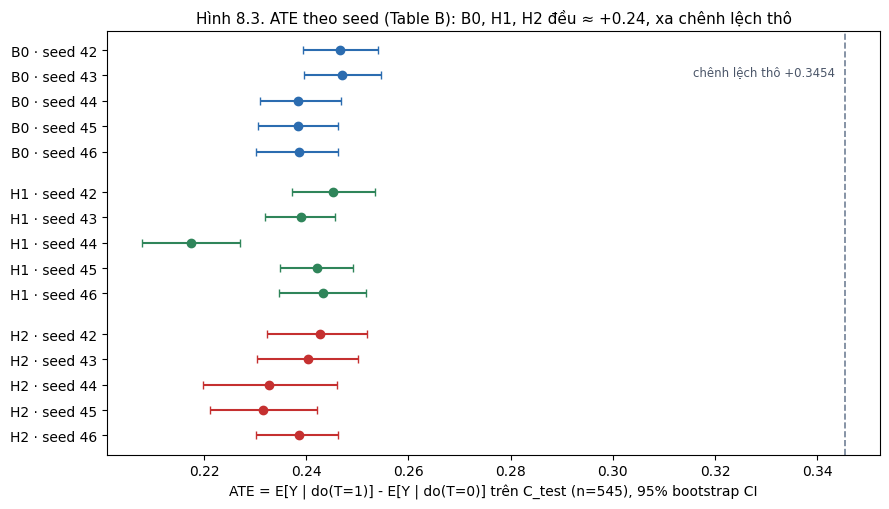

In [18]:
def ve_forest_ate_table_b(bang_b: pd.DataFrame, chenh_lech_tho: float, duong_dan_luu: Path) -> None:
    """
    Hàm này để làm gì: Vẽ forest plot ATE và 95% CI theo từng seed cho B0, H1, H2 (Table B), so với chênh lệch thô.

    Nhận vào:
        bang_b (pd.DataFrame): Table_B_Intervention.csv.
        chenh_lech_tho (float): Chênh lệch quan sát thô P(Y|T=1) - P(Y|T=0).
        duong_dan_luu (Path): Đường dẫn lưu PNG.
    """
    theo_seed = bang_b[bang_b['Seed'].astype(str).str.isdigit()].copy()
    for cot in ['ATE', 'CI_95_Low', 'CI_95_High']:
        theo_seed[cot] = theo_seed[cot].astype(float)
    mau = {'B0': '#2b6cb0', 'H1': '#2f855a', 'H2': '#c53030'}
    fig, ax = plt.subplots(figsize=(9, 5.2))
    y = 0
    nhan_y: List[str] = []
    for mo_hinh in ['B0', 'H1', 'H2']:
        con = theo_seed[theo_seed['Model'] == mo_hinh]
        for _, r in con.iterrows():
            ax.errorbar(r['ATE'], y, xerr=[[max(r['ATE'] - r['CI_95_Low'], 0.0)], [max(r['CI_95_High'] - r['ATE'], 0.0)]],  # H2: CI suy biến
                        fmt='o', color=mau[mo_hinh], capsize=3)
            nhan_y.append(f"{mo_hinh} · seed {r['Seed']}")
            y += 1
        y += 0.6
        nhan_y.append('')
    ax.axvline(chenh_lech_tho, color='#718096', ls='--', lw=1.2)
    ax.text(chenh_lech_tho - 0.002, 1.0, f'chênh lệch thô {chenh_lech_tho:+.4f}', ha='right', fontsize=8.5, color='#4a5568')
    toa_do = []
    yy = 0
    for mo_hinh in ['B0', 'H1', 'H2']:
        for _ in range(len(theo_seed[theo_seed['Model'] == mo_hinh])):
            toa_do.append(yy)
            yy += 1
        yy += 0.6
    ax.set_yticks(toa_do)
    ax.set_yticklabels([n for n in nhan_y if n])
    ax.invert_yaxis()
    ax.set_xlabel('ATE = E[Y | do(T=1)] - E[Y | do(T=0)] trên C_test (n=545), 95% bootstrap CI')
    ax.set_title('Hình 8.3. ATE theo seed (Table B): B0, H1, H2 đều ≈ +0.24, xa chênh lệch thô', fontsize=11)
    fig.tight_layout()
    fig.savefig(duong_dan_luu, dpi=150, bbox_inches='tight')
    plt.show()


ve_forest_ate_table_b(df_table_b, 0.8617 - 0.5163, THU_MUC_HINH / 'ate_forest_table_b.png')


### So sánh với bản gốc (cùng 5 split, chỉ khác ràng buộc trong $\mathbf{Z}$)
Cell dưới đặt cạnh nhau dòng tổng hợp 5 run của bản gốc (`artifacts/tables/`) và bản mới (`artifacts_rang_buoc_z/tables/`),
rồi so đồ thị từng seed: số cạnh, $\text{Pa}(Y)$, và số cạnh vi phạm thứ tự trong $\mathbf{Z}$.

In [19]:
GOC_BANG = Path('artifacts/tables')
GOC_HINH = Path('artifacts/graphs')
CAM_TRONG_Z = {(z, 'Z4') for z in ('Z1', 'Z2', 'Z3', 'Z5')} | {(z, 'Z5') for z in ('Z1', 'Z2', 'Z3')} | {(z, 'Z1') for z in ('Z2', 'Z3')}


def dong_tong_hop(duong_dan: Path, cot: List[str], nhan: str) -> pd.DataFrame:
    """Lấy 3 dòng 'Mean ± Std' (B0, H1, H2) của một bảng và gắn nhãn phiên bản."""
    bang = pd.read_csv(duong_dan)
    bang = bang[bang['Seed'].astype(str).str.startswith('Pooled')][cot].copy()
    bang['Model'] = bang['Model'].str.split(' ').str[0]
    bang.insert(1, 'Phiên bản', nhan)
    return bang


def so_sanh(ten_bang: str, cot: List[str]) -> pd.DataFrame:
    """Ghép dòng tổng hợp của bản gốc và bản ràng buộc mới cho cùng một bảng."""
    goc = dong_tong_hop(GOC_BANG / ten_bang, cot, 'Gốc')
    moi = dong_tong_hop(THU_MUC_BANG / ten_bang, cot, 'Ràng buộc Z')
    return pd.concat([goc, moi]).sort_values(['Model', 'Phiên bản'], ascending=[True, True]).reset_index(drop=True)


print('=== SO SÁNH TABLE A (trung bình ± độ lệch chuẩn, 5 run) ===')
display(so_sanh('Table_A_Prediction.csv', ['Model', 'AUROC', 'Macro_F1', 'Brier_Score', 'Delta_AUROC_vs_B0']))
print('\n=== SO SÁNH TABLE B ===')
display(so_sanh('Table_B_Intervention.csv', ['Model', 'Risk_do_T0', 'Risk_do_T1', 'ATE', 'CI_95_Low', 'CI_95_High',
                                             'Unsupported_Test_Profiles_pct']))


def tom_tat_do_thi(thu_muc: Path, ten: str) -> Dict[str, object]:
    """Đọc một DAG đã lưu và tóm tắt: số cạnh, Pa(Y), các cạnh Z -> Z vi phạm thứ tự trong Z."""
    with open(thu_muc / f'{ten}.json', encoding='utf-8') as tep:
        canh = [tuple(e) for e in json.load(tep)['edges']]
    return {'cạnh': len(canh), 'Pa(Y)': sorted(u for u, v in canh if v == 'Y'),
            'vi phạm Z': sorted(f'{u}->{v}' for (u, v) in canh if (u, v) in CAM_TRONG_Z)}


dong_do_thi = []
for s in GLOBAL_CONFIG.seeds:
    for mo_hinh in ('b0', 'h2'):
        g = tom_tat_do_thi(GOC_HINH, f'{mo_hinh}_dag_seed{s}')
        m = tom_tat_do_thi(THU_MUC_HINH, f'{mo_hinh}_dag_seed{s}')
        dong_do_thi.append({'Seed': s, 'Mô hình': mo_hinh.upper(),
                            'Cạnh (gốc → mới)': f"{g['cạnh']} → {m['cạnh']}",
                            'Pa(Y) gốc': g['Pa(Y)'], 'Pa(Y) mới': m['Pa(Y)'],
                            'Cạnh vô lý trong Z (gốc)': g['vi phạm Z'], 'Cạnh vô lý trong Z (mới)': m['vi phạm Z']})
print('\n=== SO SÁNH ĐỒ THỊ TỪNG SEED ===')
with pd.option_context('display.max_colwidth', 120):
    display(pd.DataFrame(dong_do_thi))


=== SO SÁNH TABLE A (trung bình ± độ lệch chuẩn, 5 run) ===


,Model,Phiên bản,AUROC,Macro_F1,Brier_Score,Delta_AUROC_vs_B0
0,B0,Gốc,0.7996 ± 0.0119,0.7351 ± 0.0077,0.1659 ± 0.0058,---
1,B0,Ràng buộc Z,0.7996 ± 0.0119,0.7351 ± 0.0077,0.1659 ± 0.0058,---
2,H1,Gốc,0.8012 ± 0.0130,0.7351 ± 0.0077,0.1656 ± 0.0062,+0.0016 ± 0.0025
3,H1,Ràng buộc Z,0.8012 ± 0.0130,0.7351 ± 0.0077,0.1656 ± 0.0062,+0.0016 ± 0.0025
4,H2,Gốc,0.8034 ± 0.0155,0.7261 ± 0.0277,0.1666 ± 0.0060,+0.0038 ± 0.0038
5,H2,Ràng buộc Z,0.8016 ± 0.0144,0.7309 ± 0.0202,0.1681 ± 0.0063,+0.0020 ± 0.0051



=== SO SÁNH TABLE B ===


,Model,Phiên bản,Risk_do_T0,Risk_do_T1,ATE,CI_95_Low,CI_95_High,Unsupported_Test_Profiles_pct
0,B0,Gốc,0.5495 ± 0.0114,0.7914 ± 0.0092,+0.2418 ± 0.0046,0.2341,0.2496,0.00
1,B0,Ràng buộc Z,0.5495 ± 0.0114,0.7914 ± 0.0092,+0.2418 ± 0.0046,0.2341,0.2496,0.00
2,H1,Gốc,0.5494 ± 0.0112,0.7869 ± 0.0183,+0.2374 ± 0.0114,0.2293,0.2454,0.00
3,H1,Ràng buộc Z,0.5494 ± 0.0111,0.7869 ± 0.0183,+0.2374 ± 0.0114,0.2294,0.2454,0.00
4,H2,Gốc,0.5507 ± 0.0098,0.7865 ± 0.0104,+0.2358 ± 0.0067,0.2261,0.2454,1.10
5,H2,Ràng buộc Z,0.5497 ± 0.0094,0.7869 ± 0.0099,+0.2372 ± 0.0049,0.2268,0.2473,1.91



=== SO SÁNH ĐỒ THỊ TỪNG SEED ===


,Seed,Mô hình,Cạnh (gốc → mới),Pa(Y) gốc,Pa(Y) mới,Cạnh vô lý trong Z (gốc),Cạnh vô lý trong Z (mới)
0,42,B0,11 → 11,"[T, Z2, Z3, Z5]","[T, Z2, Z3, Z5]","[Z3->Z5, Z5->Z4]",[]
1,42,H2,8 → 13,"[T, Z1, Z2, Z3, Z5]","[T, Z1, Z2, Z3, Z5]",[],[]
2,43,B0,10 → 10,"[T, Z2, Z3, Z5]","[T, Z2, Z3, Z5]","[Z3->Z5, Z5->Z4]",[]
3,43,H2,8 → 9,"[T, Z1, Z2, Z3, Z5]","[T, Z1, Z2, Z3, Z5]",[],[]
4,44,B0,11 → 10,"[T, Z2, Z3, Z5]","[T, Z2, Z3, Z5]","[Z2->Z1, Z3->Z5, Z5->Z4]",[]
5,44,H2,8 → 14,"[T, Z1, Z2, Z3, Z5]","[T, Z1, Z2, Z3, Z4, Z5]",[],[]
6,45,B0,11 → 11,"[T, Z2, Z3, Z5]","[T, Z2, Z3, Z5]","[Z3->Z5, Z5->Z4]",[]
7,45,H2,9 → 15,"[T, Z1, Z2, Z3, Z5]","[T, Z1, Z2, Z3, Z4, Z5]",[],[]
8,46,B0,12 → 11,"[T, Z2, Z3, Z5]","[T, Z2, Z3, Z5]","[Z1->Z5, Z3->Z1, Z3->Z5, Z5->Z4]",[]
9,46,H2,7 → 8,"[T, Z2, Z3, Z5]","[T, Z2, Z3, Z5]",[],[]


### Đọc kết quả
* **Cột "Cạnh vô lý trong Z (mới)"** phải rỗng ở mọi dòng: đó là kiểm tra ràng buộc đã được tôn trọng (B0 qua
  `ExpertKnowledge`, H2 qua mặt nạ $M$ — trọng số ô cấm bằng 0, cột `H2_max|W|_forbidden` ở bảng tóm tắt đồ thị).
* **ATE** của bản mới so với bản gốc: nếu chênh lệch nhỏ hơn độ dao động giữa 5 run, kết luận can thiệp **không phụ thuộc**
  vào chiều các cạnh giữa biến nền — đúng như lý thuyết, vì mọi $Z$ đều là tiền can thiệp.
* Nếu $\text{Pa}(Y)$ thay đổi, tập điều chỉnh $\text{Pa}(Y) \setminus T$ cũng thay đổi; so cột `Adjustment_Set`
  và `Overlap_Status` ở Table B để xem ảnh hưởng.
* Ràng buộc là **giả định miền**, không được kiểm chứng từ dữ liệu: dữ liệu quan sát không phân biệt được chiều giữa
  các biến cùng tầng (lớp tương đương Markov).
